# Player Dissatisfaction in Steam Reviews: What Patterns Characterize Negative Recommendations?

### A Descriptive Analysis of 113.9 Million Steam Reviews with Apache Spark

## Abstract

Steam user reviews are the most visible public record of how players judge PC games, yet a game's review score does not show where negative recommendations concentrate across the catalog or what dissatisfied players complain about. This report asks: what patterns characterize player dissatisfaction in Steam reviews? Using the DataFrame, SQL, and ML interfaces of Apache Spark, we processed the 42 GB `all_reviews.csv` file of the *100 Million+ Steam Reviews* dataset (113,883,717 reviews), removed 353,296 duplicate rows to retain 113,530,421 reviews, and measured the share of reviews that do not recommend the game by game, playtime at review, review year, and language, then compared word use in negative and positive English reviews. Overall, 14.4% of reviews are negative. The 15 most criticized games with at least 1,000 reviews are 82–91% negative, led by 三国杀 (91.0%) and including Overwatch 2 (88.7% of 204,330 reviews). Reviews written after less than one hour of play are 33.6% negative, 2.3 times the overall share, a pattern that holds within games. The share peaked at 20.7% in 2018 and ranges from 8.5% (Portuguese, Brazil) to 20.2% (Simplified Chinese) across the ten main languages. Negative English reviews are marked by words about refunds, unplayable games, anti-cheat bans, and incompetence, such as *eac* and *scam*, each over 25 times more frequent than in positive reviews. We recommend that developers monitor first-hour reviews and these complaint themes, noting that the results describe self-selected reviewers and are not causal.

## Table of Contents

1. [Introduction](#introduction)
    1. [Background](#background)
    2. [Problem Statement](#problem-statement)
    3. [Motivation](#motivation)
    4. [Scope and Report Structure](#scope)
2. [Data Source and Description](#data-source)
3. [Methodology](#methodology)
4. [Data Loading and Staging](#data-loading)
5. [Exploratory Data Analysis](#eda)
6. [Data Cleaning and Filtering](#cleaning)
7. [Games with the Highest Share of Negative Recommendations (RQ1)](#rq1)
8. [Negative Recommendations by Playtime, Year, and Language (RQ2)](#rq2)
9. [Words that Characterize Negative English Reviews (RQ3)](#rq3)
10. [Results and Discussion](#results)
11. [Conclusion](#conclusion)
12. [Recommendations](#recommendations)
13. [References](#references)

[Appendix A. Reproducibility and Supplementary Files](#appendix-a)

<a id="introduction"></a>
## 1. Introduction

<a id="background"></a>
### 1.1 Background

Steam, the digital distribution platform run by Valve Corporation, is one of the most popular places to buy and play PC games (Lin et al., 2019). In 2023, the year in which our data ends, it passed 33 million concurrent users for the first time (Valve Corporation, 2024). Any Steam user who has recorded playtime on a game can review it. Each review must state whether the reviewer recommends the game, and it can explain why in free text. Steam then combines the positive and negative reviews into the review score shown on the game's store page (Valve Corporation, n.d.-c).

These reviews matter beyond the opinion of a single player. Lin et al. (2019) note that reviews can decide a game's commercial fate, because potential buyers often base their purchasing decisions on them. Research on online retail points the same way. An improvement in a product's reviews raises its sales relative to competing sellers, and one-star reviews affect sales more strongly than five-star reviews do (Chevalier & Mayzlin, 2006). Negative reviews are also the most informative for developers, since they contain more of the complaints and bug reports that show what players dislike (Lin et al., 2019).

A review score, however, summarizes one game at one moment. It does not show where negative recommendations concentrate across the catalog. Which games draw the largest shares of them? Which kinds of reviewers are most dissatisfied? How has dissatisfaction changed over the years, and does it differ between language communities? What do dissatisfied players write about? Answering these questions requires examining all reviews together. The dataset used in this report holds 113,883,717 Steam reviews in a single 42 GB CSV file (KieranPO'C, 2023), too large to process comfortably in the memory of one machine with pandas. We therefore use Apache Spark, a unified engine for large-scale data processing, through its DataFrame, SQL, and machine-learning interfaces (Armbrust et al., 2015; Zaharia et al., 2016).

This report is descriptive. It measures how often reviews do not recommend a game and compares that share across games, reviewer groups, and words. It does not predict reviews or claim that any factor causes dissatisfaction.

<a id="problem-statement"></a>
### 1.2 Problem Statement

**What patterns characterize player dissatisfaction in Steam reviews?**

In this report, dissatisfaction is measured by negative recommendations: reviews in which the reviewer does not recommend the game (`voted_up` is false). We answer the main question through three research questions, each looking at dissatisfaction from a different angle:

1. **RQ1 (which games).** Which games with at least 1,000 reviews have the highest shares of negative recommendations? (Section 7)
2. **RQ2 (which reviewers).** How does the negative-recommendation share differ by playtime at review, review year, and review language? (Section 8)
3. **RQ3 (which complaints).** Which words appear far more often in negative English reviews than in positive ones? (Section 9)

<a id="motivation"></a>
### 1.3 Motivation

Negative recommendations have direct consequences for a game. Steam computes the review score from the balance of positive and negative reviews. A game whose score falls below 40%, into the *Mostly Negative* range, becomes less likely to be featured by Steam's recommendation algorithms (Valve Corporation, n.d.-c). Buyers also rely on reviews when deciding what to purchase (Chevalier & Mayzlin, 2006; Lin et al., 2019). Knowing where dissatisfaction concentrates is therefore useful to several groups:

- **Game developers** can see which situations go together with negative recommendations, such as the first hours of play, and which complaints recur across many games, and so decide what to fix first.
- **Publishers and community managers** can see which language communities are the most negative, which is where responses and localized support may be most needed.
- **Platforms such as Steam** can monitor dissatisfaction across the whole catalog and over time, not one game at a time.
- **Players, journalists, and researchers** get a factual description of the whole catalog that complements single-game reviews and earlier studies of smaller samples (Lin et al., 2019).

A descriptive analysis of all the reviews suits this problem for three reasons:

- **Patterns must be described before they can be explained.** Knowing which games, reviewer groups, and words stand out is the first step toward any study of why players are dissatisfied.
- **Scale matters.** Many games receive few reviews, so a sample would leave them unmeasured. A 1% sample, for instance, would leave a game with 1,000 reviews about 10. Analyzing all 113.9 million reviews keeps every game with at least 1,000 reviews and every major language in view.
- **The method is reproducible.** The pipeline uses only Spark's built-in functions and one public dataset. It can be rerun on a newer snapshot or applied to reviews from another platform.

<a id="scope"></a>
### 1.4 Scope and Report Structure

This report analyzes one file, `all_reviews.csv` from Version 2 (10 December 2023) of the dataset, which covers all games and languages in that snapshot. It adds no outside data, and it never uses or displays reviewer IDs. Its findings describe the reviews in this snapshot only. Because reviewers choose to write reviews, the results cannot show how all players feel or why any of them were dissatisfied.

The rest of the report is organized as follows. Section 2 describes the data source, and Section 3 the methodology and its design constraints. Sections 4 to 6 load, explore, and clean the data. Sections 7 to 9 answer RQ1 to RQ3 in turn, and Sections 10 to 12 discuss the results, state the conclusion, and give recommendations.

<a id="data-source"></a>
## 2. Data Source and Description

### 2.1 Source and Collection

The data is Version 2 (10 December 2023) of *100 Million+ Steam Reviews*, a dataset published on Kaggle by KieranPO'C (2023). This report reads the copy in Jojie's public data folder, `/mnt/data/public/steam-reviews/all_reviews/`, in place (Section 4). The data was collected in two stages:

- **By Steam.** A Steam user who has recorded playtime on a game can write a review that either recommends or does not recommend it, with free text explaining why (Valve Corporation, n.d.-c). Steam attaches metadata that it records itself. This includes the reviewer's playtime in the game (in total, in the last two weeks, and when the review was written), the language the reviewer chose, and creation and update timestamps. It also includes whether the game was bought on Steam or received for free, whether the review was written during Early Access, and how many users rated the review as helpful or funny (Valve Corporation, n.d.-a, n.d.-d).
- **By the dataset author.** According to the dataset description, the reviews were collected from Steam's *User Reviews – Get List* API (KieranPO'C, 2023). This public endpoint returns the reviews of one game at a time, in pages, with the fields listed in Table 2 (Valve Corporation, n.d.-d). By default, it leaves out reviews that Steam has flagged as off-topic activity ("review bombs") unless the caller asks to include them (Valve Corporation, n.d.-d). The endpoint returns reviews without the game's name, so the dataset author must have added the `game` column separately.

The data contains no reviewer names. Reviewers appear only as numeric Steam IDs, which this report drops during staging (Section 4.5) and never displays.

Table 1 lists the two files of the dataset. Only `all_reviews.csv` is analyzed. The second file, `weighted_score_above_08.csv`, is a filtered subset of the same reviews that, as its name indicates, keeps reviews with a weighted vote score above 0.8. Including it would count those reviews twice.

**Table 1.** Files in Version 2 of the dataset and their role in this report.

| File | Contents | Size | Used |
|---|---|---|---|
| `all_reviews/all_reviews.csv` | All 113,883,717 reviews, one row per review, 24 columns | 42,487,005,552 bytes (40G by `du -sch`) | Yes: the only input |
| `weighted_score_above_08.csv` | Subset of the same reviews with a weighted vote score above 0.8 | 699 MB | No: it would count the same reviews twice |

### 2.2 Fields

All 24 columns are stored as text, under a header row. A CSV field that contains commas, quotes, or line breaks, as review text often does, must be enclosed in double quotes (Shafranovich, 2005). This shapes how the file is read (Section 4.4). Table 2 describes every column, following the Steamworks documentation of the reviews API (Valve Corporation, n.d.-a, n.d.-d), and states its role in this report.

**Table 2.** Columns of `all_reviews.csv`, in file order, with their meaning and their use in this report. Playtimes are in minutes and timestamps in Unix seconds (UTC).

| # | Column | Description | Use in this report |
|---|---|---|---|
| 1 | `recommendationid` | Unique ID of the review | Key; duplicates removed (Section 6) |
| 2 | `appid` | Steam application ID of the reviewed game | RQ1 key |
| 3 | `game` | Name of the game, added by the dataset author | RQ1 labels |
| 4 | `author_steamid` | Reviewer's Steam ID | Not used, for privacy (Section 3.3) |
| 5 | `author_num_games_owned` | Number of games the reviewer owns | Exploration only |
| 6 | `author_num_reviews` | Number of public reviews the reviewer has written | Exploration only |
| 7 | `author_playtime_forever` | Reviewer's lifetime playtime in the game | Exploration only |
| 8 | `author_playtime_last_two_weeks` | Reviewer's playtime in the two weeks before collection | Exploration only |
| 9 | `author_playtime_at_review` | Reviewer's playtime when the review was written | RQ2 playtime bands |
| 10 | `author_last_played` | When the reviewer last played the game | Exploration only |
| 11 | `language` | Language the reviewer chose for the review | RQ2; RQ3 filter |
| 12 | `review` | Review text | RQ3 |
| 13 | `timestamp_created` | When the review was created | RQ2 review year |
| 14 | `timestamp_updated` | When the review was last updated | Choosing among duplicate rows |
| 15 | `voted_up` | True if the reviewer recommends the game | Outcome for all RQs |
| 16 | `votes_up` | Number of users who found the review helpful | Exploration only |
| 17 | `votes_funny` | Number of users who found the review funny | Exploration only |
| 18 | `weighted_vote_score` | Steam's helpfulness score for the review | Exploration only |
| 19 | `comment_count` | Number of comments on the review | Exploration only |
| 20 | `steam_purchase` | True if the reviewer bought the game on Steam | Exploration only |
| 21 | `received_for_free` | True if the reviewer marked the game as received for free | Exploration only |
| 22 | `written_during_early_access` | True if the review was written while the game was in Early Access | Exploration only |
| 23 | `hidden_in_steam_china` | Flag returned by the API for Steam China; not described further in the documentation | Exploration only |
| 24 | `steam_china_location` | Location field returned by the API for Steam China; not described further in the documentation | Exploration only |

### 2.3 Known Limitations of the Source

Four properties of the source limit what the data can show. Section 12.2 returns to them.

- **Reviewers select themselves.** Only players who chose to write a review are included, so every share in this report describes reviewers, not all players.
- **Only players with recorded playtime can review.** Reviews therefore come from people who launched the game through Steam (Valve Corporation, n.d.-c). Playtime counts only time tracked by the Steam client.
- **Some reviews may be missing.** Unless the dataset author changed the API's default, reviews flagged as off-topic review bombs are not included (Valve Corporation, n.d.-d). Reviews deleted before December 2023 are absent, and edits made after collection are not reflected.
- **Our shares are not Steam's review scores.** Steam's score counts only reviews from accounts that purchased the game, not key activations (Valve Corporation, n.d.-c). This report counts every review in the file, so its negative shares need not match the scores shown on store pages.

<a id="methodology"></a>
## 3. Methodology

### 3.1 Pipeline Overview

Figure 1 summarizes the methodology as eight steps in three stages. Below the figure, each step is described and linked to the section where it is carried out.

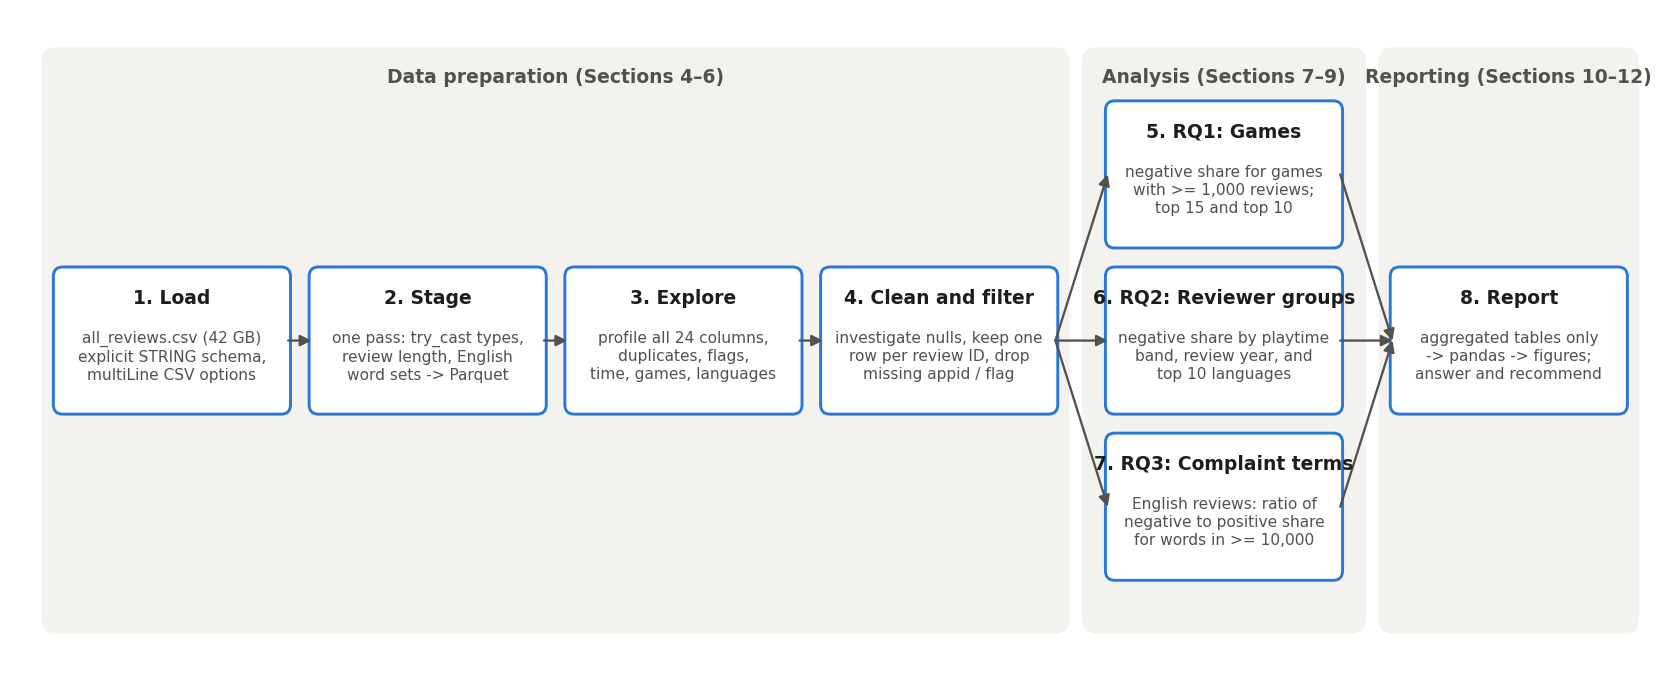

In [1]:
import os

from IPython.display import Image, display

# Figure 1 is drawn by the supplementary script make_pipeline_diagram.py
from make_pipeline_diagram import draw_pipeline

os.makedirs('figures', exist_ok=True)
PIPELINE_FIGURE = os.path.join('figures', 'pipeline_overview.png')
draw_pipeline(PIPELINE_FIGURE)
display(Image(PIPELINE_FIGURE, width=950))

**Figure 1.** The eight steps of the methodology, grouped into data preparation, analysis, and reporting. Steps 1–2 read the 42 GB raw file once and stage a compact typed table; steps 3–4 explore and clean it; steps 5–7 answer RQ1–RQ3 in Spark; and only aggregated tables reach pandas in step 8. The supplementary script `make_pipeline_diagram.py` draws this figure.

1. **Load (Section 4).** Read `all_reviews.csv` in place with an explicit schema that types every column as `STRING`, and CSV options for quoted, multi-line review text.
2. **Stage (Section 4.5).** In a single pass over the raw file, convert each numeric column with `try_cast`, record values that fail to convert, measure review length, split each English review into its set of distinct content words with Spark ML, and write the result to a scratch Parquet table. The review text and reviewer IDs are not kept.
3. **Explore (Section 5).** Profile all 24 raw columns, and examine duplicates, flag encodings, time coverage, games, languages, playtime, and review length.
4. **Clean and filter (Section 6).** Investigate why values are missing, then keep valid review IDs, keep one row per review ID, and drop rows without a game ID or a recommendation flag, logging the count and proportion kept after each step.
5. **RQ1 (Section 7).** Compute the negative-recommendation share (Equation 1) for each game with at least 1,000 retained reviews; rank the top 15 by share, with 95% Wilson intervals (Equation 2), and the top 10 by number of negative reviews.
6. **RQ2 (Section 8).** Compute the same share for five playtime-at-review bands, each review year, and the 10 most common languages, both pooled and averaged over games.
7. **RQ3 (Section 9).** For English reviews, compute how much more often each word appears in negative than in positive reviews (Equation 3) and report the 20 highest ratios among words found in at least 10,000 reviews.
8. **Report (Sections 10–12).** Move only aggregated tables to pandas, plot them, and turn them into answers, a conclusion, and recommendations.

Sections 7.5, 8.4, and 9.3 repeat steps 5–7 under alternative assumptions to test how robust the findings are.

### 3.2 Definitions

The analysis uses three measures, defined once here and referred to by their equation numbers in the rest of the report.

**Negative-recommendation share.** For any group $g$ of retained reviews (a game, a playtime band, a year, or a language),

$$s_g = \frac{n^{-}_{g}}{n_g}, \tag{1}$$

where $n_g$ is the number of retained reviews in $g$ and $n^{-}_{g}$ the number of those with `voted_up` false. The overall share $s$ uses all retained reviews and appears as a reference line in Figures 7 and 9–11.

**Uncertainty of a share.** A share computed from few reviews is unstable, so each game's share in Section 7 carries a 95% Wilson score interval (Wilson, 1927),

$$\frac{1}{1 + z^2/n_g}\left(s_g + \frac{z^2}{2n_g} \pm z\sqrt{\frac{s_g(1 - s_g)}{n_g} + \frac{z^2}{4n_g^2}}\right), \qquad z = 1.96. \tag{2}$$

**Playtime bands.** Playtime at review is converted from minutes to hours and grouped into the bands of the game plan: under 1 h, 1–10 h, 10–50 h, 50–200 h, and 200+ h. Each band includes its lower bound and excludes its upper bound. Reviews with missing playtime would form a separate *Unknown* band; Section 5.8 shows that this snapshot has none.

**Review year.** The calendar year of `timestamp_created` in UTC. The final year is labeled *partial* if the last review in the file was created before 31 December.

**Term ratio.** Among English reviews with at least one content word, let $N^{-}$ and $N^{+}$ be the numbers of negative and positive reviews, and $d^{-}_{w}$ and $d^{+}_{w}$ the numbers of negative and positive reviews that contain word $w$ at least once. The term ratio is

$$r_w = \frac{d^{-}_{w} / N^{-}}{d^{+}_{w} / N^{+}}, \tag{3}$$

so $r_w = 3$ means that a negative review is three times as likely as a positive review to contain $w$. Only words with $d^{-}_{w} + d^{+}_{w} \geq 10{,}000$ are ranked, so that ratios are not driven by rare words.

### 3.3 Design Constraints and Choices

Processing 42 GB of quoted, multi-line text on one shared server imposes constraints that shaped every step of the pipeline. Table 3 lists each constraint, the choice made, its justification, and the alternative considered. The main alternatives are tested with data in Sections 4.4, 7.5, 8.4, and 9.3.

**Table 3.** Design constraints, the choices made, their justification, and the alternatives considered.

| Constraint | Choice | Justification | Alternative considered |
|---|---|---|---|
| One 42 GB CSV whose review text contains commas, quotes, and line breaks | `multiLine=True`, `quote='"'`, `escape='"'` | A field with line breaks or quotes is enclosed in double quotes, and a quote inside it is doubled (Shafranovich, 2005). `multiLine` lets one record span several lines, and `escape='"'` replaces Spark's default backslash escape (Apache Software Foundation, n.d.-a). | Reading without `multiLine` splits the file into many partitions, but every line break inside a review starts a broken record: 113,885,601 records instead of 113,883,717 (Table 6). |
| A file read with `multiLine` cannot be split, so each scan of it runs on one core | Scan the raw file **once** and stage a compact Parquet table (Section 4.5) | Parquet is columnar and splittable, so later steps read only the columns they need, in parallel (lecture: *Working with Parquet files*). After staging, no step of the final run takes more than 14 minutes (Table 21). | Persisting the raw DataFrame (lecture: *Persistence*) would need about 40 GB of memory or disk, and it is lost whenever the kernel restarts. |
| Unknown encodings and possibly malformed values | Read every column as `STRING`, convert with `try_cast`, and count the values that fail | Separates *missing* values from *malformed* ones (Section 6.1). Under ANSI mode, the default since Spark 4.0, a plain cast of a malformed value stops the job with an error (Apache Software Foundation, n.d.-c). | `inferSchema` needs an extra pass over all 42 GB (lecture: *Spark DataFrame*) and still cannot report malformed values. |
| Limited storage on Jojie, and the instruction not to copy raw data | The staged table keeps typed fields, review length, and English word sets only. It drops the review text and reviewer IDs, lives in `scratch/`, is deleted after the final run, and is never submitted. | Keeps the staged table at about 8 GB (Section 4.1), about a fifth of the raw file. | Staging the full text would take nearly as much space as the raw file. |
| Driver memory | Only aggregated tables move to pandas, through Arrow (lecture: *Spark DataFrame and pandas*) | The 113.9 million review-level rows would not fit in the driver's memory. | `toPandas()` on review-level data. |
| Duplicate review IDs | Keep one row per ID, chosen with a window function: the most recently updated copy, then the lowest `appid` | Deterministic. It keeps the reviewer's latest version where copies differ, and otherwise counts a review that is listed under several games only once (Section 5.3). | `dropDuplicates()` keeps an arbitrary row. |
| Shares of games with few reviews are unstable | At least 1,000 reviews per game, plus Wilson intervals (Equation 2) | Prevents games with a 100% share from a handful of reviews from topping the ranking. | 500 and 5,000 reviews, and ranking by the interval's lower bound (Section 7.5). |
| Pooled shares are dominated by a few heavily reviewed games | Also report game-averaged shares | Shows whether a group pattern holds across games or comes from a few large ones. | Section 8.4. |
| Rare words give extreme ratios | Words in at least 10,000 reviews | Stable ratios with enough evidence behind each. | 2,000 and 50,000 reviews (Section 9.3). |
| Reproducible review years | Session time zone set to UTC | Unix timestamps convert to the same year on any machine. | The server's local time zone would shift reviews written near midnight on 31 December into the wrong year. |
| Python UDFs are slow, since each row is serialized to Python | Built-in Spark SQL functions and Spark ML transformers only | Work stays in Spark's JVM (lecture: *User-defined functions*). | Python or pandas UDFs. |
| Privacy and anonymity | Reviewer IDs are dropped during staging and never shown; paths contain no usernames | Required by the instructions and the game plan. | None. |

Table 4 maps each technique to the section where it is used and states whether it was covered in the lectures.

**Table 4.** Techniques used, where they appear, and whether they come from the lectures or go beyond them.

| Technique | Section | Source |
|---|---|---|
| `SparkSession` in local mode with all cores; Arrow for `toPandas()` | 4.1 | Lecture: Spark DataFrame API |
| Explicit DDL schema instead of `inferSchema` | 4.4 | Lecture: Spark DataFrame API |
| Parquet staging and column pruning | 4.5 | Lecture: Spark DataFrame API |
| `groupBy` and `agg`, `filter`, `explode`, regular expressions | 5–9 | Lecture: Spark DataFrame API |
| Temporary views and `spark.sql` queries | 6.4, 7, 9 | Lecture: Spark SQL API |
| Persistence of a small, reused aggregate | 5.6 | Lecture: Spark DataFrame API |
| CSV options for multi-line, quoted text; `try_cast`; `percentile_approx`; `approx_count_distinct` | 4–5 | Beyond: Spark documentation (Apache Software Foundation, n.d.-a) |
| Window functions for deterministic de-duplication | 6.3 | Beyond |
| Spark ML `RegexTokenizer` and `StopWordsRemover`; `Bucketizer` | 4.5, 5.8 | Beyond (Apache Software Foundation, n.d.-b) |
| Wilson score intervals; game-averaged shares; sensitivity analysis | 7–9 | Beyond: statistics |

### 3.4 Tools and Environment

The final run used Apache Spark 4.1.1 in local mode (`local[*]`) on Jojie, the course's JupyterLab server, with 4 cores, Python 3.12, and 16 GB of driver memory (Section 4.1). PySpark provides the DataFrame, SQL, and ML interfaces. pandas and NumPy handle the small aggregated tables, and matplotlib draws the figures. Figure 1 is drawn by the supplementary script `make_pipeline_diagram.py`. Appendix A lists the software versions and the runtime of each expensive step (Table 21). The single staging pass over the raw file is the slowest step of the pipeline, because it runs on one core (Section 4.4 and Table 3).

<a id="data-loading"></a>
## 4. Data Loading and Staging

This section prepares the data in five steps. It starts Spark and fixes the parameters of the game plan (Sections 4.1 and 4.2), confirms the size of the raw input (Section 4.3), reads the CSV with an explicit schema (Section 4.4), and stages it once as a compact Parquet table (Section 4.5). The raw file is read in place from Jojie's public data folder, and no raw or processed data is copied or submitted with this report.

### 4.1 Libraries, Plotting Style, and Spark Session

In [2]:
import csv
import os
import re
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from functools import reduce

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import FuncFormatter
from pyspark.ml.feature import Bucketizer, RegexTokenizer, StopWordsRemover
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 60)

# One plotting style for every figure (same palette as our Lab 1 report)
PRIMARY = '#2a78d6'  # data marks
ACCENT = '#eb6834'   # highlighted marks, e.g. a partial year
MUTED = '#52514e'    # reference lines and annotations
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.dpi': 110,
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelcolor': MUTED,
    'axes.edgecolor': '#b5b4ae',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e6e5e0',
    'grid.linewidth': 0.8,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
})

# Wall-clock time of the expensive steps, reported in Appendix A
RUNTIMES = {}


@contextmanager
def timed(label):
    """Measure the wall-clock time of a block and store it in RUNTIMES.

    Parameters
    ----------
    label : str
        Name of the step, used as the key in ``RUNTIMES``.
    """
    start = time.perf_counter()
    yield
    RUNTIMES[label] = time.perf_counter() - start
    print(f'{label}: {RUNTIMES[label] / 60:.1f} min')

In [3]:
spark = (
    SparkSession.builder
    .master('local[*]')
    .appName('steam-review-dissatisfaction')
    # Arrow speeds up toPandas() on the aggregated tables (lecture)
    .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
    # Convert Unix timestamps in UTC so review years are reproducible
    .config('spark.sql.session.timeZone', 'UTC')
    # Keep stage progress bars out of the report's cell outputs
    .config('spark.ui.showConsoleProgress', 'false')
    # In local mode the driver runs every task (see the text below)
    .config('spark.driver.memory', '16g')
    .config('spark.sql.shuffle.partitions', '400')
    # Parquet's vectored reads hold large off-heap buffers that ran out
    # of memory on the staged table; plain reads are fast enough here
    .config('spark.hadoop.parquet.hadoop.vectored.io.enabled', 'false')
    .getOrCreate()
)
spark.sparkContext.setLogLevel('OFF')

print(f'Spark version: {spark.version}; '
      f'{spark.sparkContext.defaultParallelism} cores available')

Spark version: 4.1.1; 4 cores available


Spark runs in local mode (`local[*]`), so a single JVM uses every available core of the machine, as in the course notebooks; the final run on Jojie had 4. Six settings differ from Spark's defaults, for the reasons given below and in Table 3:

- **Arrow** speeds up the conversion of Spark results to pandas, which the report uses only for small aggregated tables (lecture: *Spark DataFrame and pandas*).
- **The UTC time zone** makes Unix timestamps convert to the same calendar year on any machine.
- **Disabled progress bars** keep Spark's job progress messages out of the report's cell outputs.
- **16 GB of driver memory.** In local mode, the driver also runs every task, and the de-duplication in Section 6.4 sorts more than 100 million rows. With Spark's default of 1 GB, it would spill to disk constantly.
- **400 shuffle partitions**, twice Spark's default of 200, keep each partition of the largest shuffle small enough to sort in memory.
- **Vectored Parquet reads are turned off.** Since Spark 4, Parquet reads each block of a file into memory outside the Java heap. The staged table is a single file of about 8 GB with blocks of up to 230 MB, and in a test run these buffers were not released fast enough: they filled the memory limit and stopped Spark. With plain reads, the staged table is read without memory errors, and profiling all of its columns takes 7.4 minutes (Table 21).

### 4.2 Paths and Analysis Parameters

The next cell defines every threshold of the game plan once, so that all sections use the same values, and it lists the alternatives tested in Sections 7.5, 8.4, and 9.3 next to them. `DEV_ROW_LIMIT` reads only the first rows of the file. This made it possible to test the whole notebook in minutes before the full run, and it is `None` in the final run. The two intermediate tables are written to a `scratch` folder, which is deleted after the final run and never submitted.

In [4]:
# Raw data read in place from the dataset folder
RAW_DIR = '/mnt/data/public/steam-reviews/all_reviews'
RAW_FILE = os.path.join(RAW_DIR, 'all_reviews.csv')

# Development switch: read only the first N reviews to test the notebook
# quickly (e.g. 200_000). Must be None for the final run.
DEV_ROW_LIMIT = None

# Intermediate Parquet tables (processed data): never submitted, and
# deleted after the final run
SCRATCH_DIR = 'scratch'
RUN_TAG = f'dev{DEV_ROW_LIMIT}' if DEV_ROW_LIMIT else 'full'
STAGED_PATH = os.path.join(SCRATCH_DIR, f'reviews_staged_{RUN_TAG}.parquet')
CLEAN_PATH = os.path.join(SCRATCH_DIR, f'reviews_clean_{RUN_TAG}.parquet')
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

# Analysis parameters fixed in the accepted game plan
MIN_GAME_REVIEWS = 1_000   # RQ1: minimum retained reviews per game
TOP_GAMES_BY_SHARE = 15    # RQ1: games ranked by negative share
TOP_GAMES_BY_COUNT = 10    # RQ1: games ranked by negative reviews
TOP_LANGUAGES = 10         # RQ2: most common review languages
MIN_TERM_REVIEWS = 10_000  # RQ3: reviews that must contain a word
TOP_TERMS = 20             # RQ3: words ranked by term ratio

# Playtime-at-review bands: (lower bound in hours, inclusive; label)
PLAYTIME_BANDS = [
    (0, 'Under 1 h'),
    (1, '1–10 h'),
    (10, '10–50 h'),
    (50, '50–200 h'),
    (200, '200+ h'),
]
UNKNOWN_BAND = 'Unknown'
BAND_ORDER = [label for _, label in PLAYTIME_BANDS] + [UNKNOWN_BAND]

# Alternative assumptions explored in Sections 7.5, 8.4, and 9.3
GAME_THRESHOLDS = [500, 1_000, 5_000]
MIN_GAME_REVIEWS_PER_GROUP = 100
TERM_THRESHOLDS = [2_000, 10_000, 50_000]

### 4.3 Raw Input Size

The raw input must be between 16 and 50 GB. The next cell measures `all_reviews.csv` with `du -sch`, and Figure 2 shows the same command run in a terminal.

40G	/mnt/data/public/steam-reviews/all_reviews/all_reviews.csv
40G	total



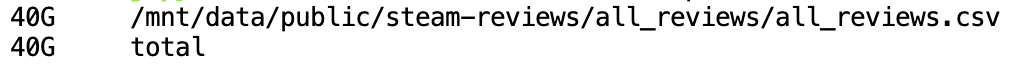

In [44]:
def show_disk_usage(path):
    """Print the output of ``du -sch`` for a file or folder.

    Parameters
    ----------
    path : str
        File or folder to measure.
    """
    result = subprocess.run(['du', '-sch', path], capture_output=True,
                            text=True, check=True)
    print(result.stdout)


show_disk_usage(RAW_FILE)

# Terminal screenshot
DU_SCREENSHOT = os.path.join(FIG_DIR, 'du_sch_raw_data.png')
if os.path.exists(DU_SCREENSHOT):
    display(Image(DU_SCREENSHOT, width=600))
else:
    print(f'Missing terminal screenshot as {DU_SCREENSHOT}')

**Figure 2.** Terminal output of `du -sch` on the raw input, `all_reviews.csv`. The file occupies 40G (42,487,005,552 bytes), within the required 16–50 GB. It is the only raw file that the notebook reads.

### 4.4 Reading the CSV with an Explicit Schema

The file is read with an explicit schema instead of `inferSchema`, which would need an extra pass over all 42 GB just to guess the column types (lecture: *Spark DataFrame*). Three decisions define how it is read:

- **The header is checked first.** When a schema is supplied, Spark applies it to the columns by position and ignores the header line (Apache Software Foundation, n.d.-a). A difference in column order would therefore mislabel columns without any error, so the first cell below compares the header with the 24 names of Table 2 before reading.
- **Every column is read as `STRING`.** Types are assigned in Section 4.5 with `try_cast`, which returns null for a value that cannot be converted. As a result, a malformed value is counted (Table 7) instead of silently becoming null or, under the ANSI mode that Spark 4 enables by default, stopping the job with an error (Apache Software Foundation, n.d.-c).
- **The CSV options match how review text is stored.** A field containing commas, line breaks, or quotes is enclosed in double quotes, and a quote inside the field is written twice (Shafranovich, 2005). `multiLine=True` lets one record span several lines, and `escape='"'` replaces Spark's default backslash escape with the doubled quote (Apache Software Foundation, n.d.-a). `mode='PERMISSIVE'` keeps a record that cannot be parsed completely and sets its unparsable fields to null, so that any problem surfaces in Section 5 instead of stopping the read.

In [6]:
# Columns of all_reviews.csv in file order (Table 2)
RAW_COLUMNS = [
    'recommendationid', 'appid', 'game', 'author_steamid',
    'author_num_games_owned', 'author_num_reviews',
    'author_playtime_forever', 'author_playtime_last_two_weeks',
    'author_playtime_at_review', 'author_last_played', 'language',
    'review', 'timestamp_created', 'timestamp_updated', 'voted_up',
    'votes_up', 'votes_funny', 'weighted_vote_score', 'comment_count',
    'steam_purchase', 'received_for_free', 'written_during_early_access',
    'hidden_in_steam_china', 'steam_china_location',
]

# Check the header line before reading: Spark would otherwise apply our
# names to the columns by position without complaint
with open(RAW_FILE, encoding='utf-8', newline='') as raw_csv:
    header = next(csv.reader(raw_csv))
print(f'{len(header)} columns in the header')
assert header == RAW_COLUMNS, f'Update RAW_COLUMNS to match: {header}'

24 columns in the header


In [7]:
# Every column is read as text; Section 4.5 assigns the real types
RAW_SCHEMA = ', '.join(f'`{name}` STRING' for name in RAW_COLUMNS)

raw_reviews = spark.read.csv(
    RAW_FILE,
    schema=RAW_SCHEMA,
    header=True,
    multiLine=True,    # review text can contain line breaks
    quote='"',
    escape='"',        # quotes inside text are doubled ("") as in RFC 4180
    mode='PERMISSIVE',
)
if DEV_ROW_LIMIT:
    raw_reviews = raw_reviews.limit(DEV_ROW_LIMIT)

n_raw_partitions = raw_reviews.rdd.getNumPartitions()
print(f'Partitions of the raw CSV: {n_raw_partitions}')

Partitions of the raw CSV: 1


In [8]:
# Design check (Table 3): the same file read without multiLine. Spark can
# split it into many partitions, but a line break inside a review then
# starts a new, broken record. Skipped in development runs, which read
# only the first rows of the file.
n_single_line_partitions, n_single_line_rows = None, None
if DEV_ROW_LIMIT is None:
    single_line = spark.read.csv(RAW_FILE, schema=RAW_SCHEMA, header=True,
                                 quote='"', escape='"', mode='PERMISSIVE')
    n_single_line_partitions = single_line.rdd.getNumPartitions()
    with timed('Count records without multiLine (parallel)'):
        n_single_line_rows = single_line.count()
    print(f'Without multiLine: {n_single_line_partitions} partitions, '
          f'{n_single_line_rows:,} records')

Count records without multiLine (parallel): 11.9 min
Without multiLine: 317 partitions, 113,885,601 records


With `multiLine=True`, the raw CSV is read as a single partition. A file read this way cannot be split: because a review may contain line breaks, Spark cannot tell where a record starts without parsing the file from its beginning. The whole 42 GB file is therefore processed by a single task on one core. Read without `multiLine`, the same file splits into 317 partitions that are counted in parallel (11.9 minutes on four cores, Table 21), but every line break inside a review then starts a new record, which inflates the row count (Table 6). Correct records matter more than parallelism, so the report keeps `multiLine=True` and limits the cost of the single-core read by scanning the file only once (Section 4.5).

### 4.5 Staging a Typed Parquet Table

Because every scan of the raw file runs on one core, the notebook reads it only once and writes the result to a compact Parquet table in the scratch folder. Parquet stores data by column and can be split, so every later step reads only the columns it needs, in parallel on all cores (lecture: *Working with Parquet files*). The single pass does five things:

1. It converts the 14 numeric columns with `try_cast`, to `BIGINT` for IDs, counts, and timestamps and to `DOUBLE` for playtimes and the helpfulness score.
2. It records, in a list column `cast_failures`, the name of every numeric column whose non-empty raw value could not be converted.
3. It replaces the review text with its length and the reviewer's Steam ID with a flag recording whether one was present, as committed in the game plan.
4. For English reviews only, it tokenizes the text and keeps the set of distinct content words (Section 9.1). Doing this here avoids a second single-core pass over the raw text for RQ3.
5. It keeps the eight text and flag columns as raw strings. The flags are converted in Section 6, after their encodings are examined (Section 5.4).

Dropping the review text and reviewer IDs keeps the staged table at about 8 GB, compared with 40 GB for the raw file. Because it runs on one core, the staging pass is the slowest step of the pipeline. If the staged table already exists, the cell reuses it instead of reading the raw file again. The final run did so: it reused the table written by an earlier full pass over the file, as the message below the cell states, so Table 21 does not time the staging pass.

In [9]:
# Numeric raw columns and the type each one is converted to
NUMERIC_TYPES = {
    'recommendationid': 'BIGINT',
    'appid': 'BIGINT',
    'author_num_games_owned': 'BIGINT',
    'author_num_reviews': 'BIGINT',
    'author_playtime_forever': 'DOUBLE',
    'author_playtime_last_two_weeks': 'DOUBLE',
    'author_playtime_at_review': 'DOUBLE',
    'author_last_played': 'BIGINT',
    'timestamp_created': 'BIGINT',
    'timestamp_updated': 'BIGINT',
    'votes_up': 'BIGINT',
    'votes_funny': 'BIGINT',
    'weighted_vote_score': 'DOUBLE',
    'comment_count': 'BIGINT',
}
# Text and flag columns, kept as raw strings; flags are converted in
# Section 6, after their encodings are examined in Section 5.4
TEXT_COLUMNS = [
    'game', 'language', 'voted_up', 'steam_purchase', 'received_for_free',
    'written_during_early_access', 'hidden_in_steam_china',
    'steam_china_location',
]


def try_cast(column, sql_type):
    """Convert a STRING column, giving null when a value does not parse.

    Parameters
    ----------
    column : str
        Name of a raw STRING column.
    sql_type : str
        Spark SQL type to convert to, such as ``'BIGINT'``.

    Returns
    -------
    pyspark.sql.Column
        The converted column.
    """
    return F.expr(f'try_cast(`{column}` AS {sql_type})')


# RQ3 tokenizer (Section 9.1): lowercase, split on anything that is not a
# letter, drop one-letter tokens, then remove Spark's English stop words
tokenizer = RegexTokenizer(inputCol='english_text', outputCol='tokens',
                           pattern='[^a-z]+', gaps=True, toLowercase=True,
                           minTokenLength=2)
stop_word_remover = StopWordsRemover(inputCol='tokens',
                                     outputCol='content_words')

# Only English reviews are tokenized; other rows get an empty string
english_text = F.when(F.col('language') == 'english',
                      F.coalesce(F.col('review'), F.lit(''))).otherwise('')

# Name of every numeric column whose non-null value failed to convert
cast_failures = F.filter(
    F.array(*[
        F.when(F.col(name).isNotNull() & try_cast(name, sql_type).isNull(),
               F.lit(name))
        for name, sql_type in NUMERIC_TYPES.items()
    ]),
    lambda name: name.isNotNull(),
)

staged = (
    stop_word_remover.transform(
        tokenizer.transform(
            raw_reviews.withColumn('english_text', english_text)))
    .select(
        *[try_cast(name, sql_type).alias(name)
          for name, sql_type in NUMERIC_TYPES.items()],
        *TEXT_COLUMNS,
        # Reviewer IDs are not kept, only whether one was present
        F.col('author_steamid').isNotNull().alias('has_author_steamid'),
        F.length('review').alias('review_length'),
        cast_failures.alias('cast_failures'),
        # Distinct content words of English reviews; null for other rows
        F.when(F.size('content_words') > 0,
               F.array_distinct('content_words')).alias('words'),
    )
)

# Spark writes _SUCCESS only after the whole table is written; a folder
# without it is left over from an interrupted run and is rewritten
if os.path.exists(os.path.join(STAGED_PATH, '_SUCCESS')):
    print(f'Reusing the staged table in {STAGED_PATH}')
else:
    with timed('Stage the raw CSV as Parquet (single pass)'):
        staged.write.parquet(STAGED_PATH, mode='overwrite')

reviews_staged = spark.read.parquet(STAGED_PATH)
reviews_staged.printSchema()

Reusing the staged table in scratch/reviews_staged_full.parquet
root
 |-- recommendationid: long (nullable = true)
 |-- appid: long (nullable = true)
 |-- author_num_games_owned: long (nullable = true)
 |-- author_num_reviews: long (nullable = true)
 |-- author_playtime_forever: double (nullable = true)
 |-- author_playtime_last_two_weeks: double (nullable = true)
 |-- author_playtime_at_review: double (nullable = true)
 |-- author_last_played: long (nullable = true)
 |-- timestamp_created: long (nullable = true)
 |-- timestamp_updated: long (nullable = true)
 |-- votes_up: long (nullable = true)
 |-- votes_funny: long (nullable = true)
 |-- weighted_vote_score: double (nullable = true)
 |-- comment_count: long (nullable = true)
 |-- game: string (nullable = true)
 |-- language: string (nullable = true)
 |-- voted_up: string (nullable = true)
 |-- steam_purchase: string (nullable = true)
 |-- received_for_free: string (nullable = true)
 |-- written_during_early_access: string (nullable

In [10]:
# First rows of the staged table (no reviewer IDs or review text)
display(reviews_staged.limit(5).toPandas())

,recommendationid,appid,author_num_games_owned,author_num_reviews,author_playtime_forever,author_playtime_last_two_weeks,author_playtime_at_review,author_last_played,timestamp_created,timestamp_updated,...,voted_up,steam_purchase,received_for_free,written_during_early_access,hidden_in_steam_china,steam_china_location,has_author_steamid,review_length,cast_failures,words
0,148919893,10,0,3,197.0,197.0,197.0,1698336369,1698336397,1698336397,...,1,1,0,0,1,None,True,8,[],None
1,148919350,10,0,21,441.0,37.0,441.0,1698335809,1698335821,1698335821,...,1,1,0,0,1,None,True,10,[],None
2,148913051,10,7,1,1440.0,1440.0,1313.0,1698338635,1698329862,1698329862,...,1,1,0,0,1,None,True,18,[],None
3,148912714,10,11,4,1636.0,83.0,1612.0,1698341834,1698329555,1698329555,...,1,1,0,0,1,None,True,3,[],None
4,148912575,10,0,2,197.0,41.0,197.0,1698329401,1698329419,1698329419,...,1,1,0,0,1,None,True,12,[],"[goat, game]"


**Table 5.** First five rows of the staged table. Numeric columns are typed, flags are still raw strings, `cast_failures` lists the columns whose raw value could not be converted, and `words` holds the distinct content words of English reviews.

Table 5 shows that the staged table has the intended structure. IDs, counts, playtimes, and timestamps are numeric, the flags remain raw strings, and `words` is filled for English reviews only. Neither reviewer IDs nor review text appear in it.

<a id="eda"></a>
## 5. Exploratory Data Analysis

This section describes the raw data as staged in Section 4.5, before any cleaning, so that every decision in Section 6 rests on evidence. It first reports the size of the data and profiles all 24 raw columns (Sections 5.1 and 5.2). It then examines the properties the analysis depends on: duplicate review IDs, the encoding of the recommendation flag, when reviews were written, how reviews are spread across games and languages, playtime at review, and review text (Sections 5.3 to 5.9).

### 5.1 Size and Structure

In [11]:
# Count the staged reviews once; later shares are relative to n_raw
with timed('Count staged rows'):
    n_raw = reviews_staged.count()

# Table 6: size and structure of the raw input
display(pd.Series({
    'File': os.path.basename(RAW_FILE),
    'Size on disk (GB)': f'{os.path.getsize(RAW_FILE) / 1e9:,.1f}',
    'Columns in the raw file': len(RAW_COLUMNS),
    'Reviews (rows) read': f'{n_raw:,}',
    'Reviews in the game plan': '113,883,717',
    'Records if read without multiLine': (
        '–' if n_single_line_rows is None else f'{n_single_line_rows:,}'),
    'Partitions of the raw CSV': n_raw_partitions,
    'Partitions without multiLine': (
        '–' if n_single_line_partitions is None
        else n_single_line_partitions),
    'Partitions of the staged table':
        reviews_staged.rdd.getNumPartitions(),
}, name='value').to_frame())

Count staged rows: 0.0 min


,value
File,all_reviews.csv
Size on disk (GB),42.5
Columns in the raw file,24
Reviews (rows) read,"113,883,717"
Reviews in the game plan,"113,883,717"
Records if read without multiLine,"113,885,601"
Partitions of the raw CSV,1
Partitions without multiLine,317
Partitions of the staged table,63


**Table 6.** Size and structure of the raw input: the number of reviews read, the number of records Spark finds if the file is read without `multiLine` (Section 4.4), and the number of Spark partitions in each case and after staging.

The staged table holds 113,883,717 reviews in 24 raw columns, exactly the number reported for this file in our game plan. Read without `multiLine`, the same file yields 113,885,601 records, 1,884 more than the correct count. The extra records are fragments of reviews that contain line breaks. The difference is small, so few reviews contain line breaks, but each of them would be split into broken rows, which confirms the reading choices of Section 4.4. The staged Parquet table, in contrast, is split into 63 partitions, so every query from this point on runs in parallel on all cores.

### 5.2 Profile of All Raw Columns

In [12]:
def profile_columns(df):
    """Compute simple statistics for all 24 raw columns in one pass.

    Numeric columns get non-null count, approximate distinct count, min,
    approximate median, mean, and max. Text columns get non-null and
    approximate distinct counts. ``review`` is summarized by its length,
    and ``author_steamid`` only by how often it is present.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        The staged table.

    Returns
    -------
    pandas.DataFrame
        One row per raw column, in file order.
    """
    numeric = [(name, name) for name in NUMERIC_TYPES]
    numeric.append(('review', 'review_length'))
    aggregations = [F.count('*').alias('rows')]
    for raw_name, column in numeric:
        aggregations += [
            F.count(column).alias(f'{raw_name}:non-null'),
            F.approx_count_distinct(column).alias(f'{raw_name}:distinct'),
            F.min(column).alias(f'{raw_name}:min'),
            F.percentile_approx(column, 0.5).alias(f'{raw_name}:median'),
            F.mean(column).alias(f'{raw_name}:mean'),
            F.max(column).alias(f'{raw_name}:max'),
        ]
    for name in TEXT_COLUMNS:
        aggregations += [
            F.count(name).alias(f'{name}:non-null'),
            F.approx_count_distinct(name).alias(f'{name}:distinct'),
        ]
    aggregations.append(F.sum(F.col('has_author_steamid').cast('int'))
                        .alias('author_steamid:non-null'))

    stats = df.agg(*aggregations).first().asDict()
    n_rows = stats.pop('rows')
    table = {}
    for key, value in stats.items():
        column, statistic = key.split(':')
        table.setdefault(column, {})[statistic] = value
    profile = pd.DataFrame.from_dict(table, orient='index')
    profile.insert(1, 'missing %', 1 - profile['non-null'] / n_rows)
    return profile.reindex(RAW_COLUMNS)


with timed('Profile all raw columns'):
    column_profile = profile_columns(reviews_staged)

# Raw values that could not be converted to their numeric type
failed_casts = (reviews_staged
                .select(F.explode('cast_failures').alias('column'))
                .groupBy('column').count()
                .toPandas().set_index('column')['count'])
column_profile.insert(2, 'failed casts',
                      failed_casts.reindex(column_profile.index))
column_profile.loc[list(NUMERIC_TYPES), 'failed casts'] = (
    column_profile.loc[list(NUMERIC_TYPES), 'failed casts'].fillna(0))

display(column_profile.style.format({
    'non-null': '{:,.0f}', 'missing %': '{:.2%}', 'failed casts': '{:,.0f}',
    'distinct': '{:,.0f}', 'min': '{:,.4g}', 'median': '{:,.4g}',
    'mean': '{:,.4g}', 'max': '{:,.4g}',
}, na_rep='–'))

print(f'Values that failed to convert, all numeric columns: '
      f'{int(failed_casts.sum()):,}')

Profile all raw columns: 7.4 min


,non-null,missing %,failed casts,distinct,min,median,mean,max
recommendationid,"113,883,717",0.00%,0,"108,657,446",43,8.341e+07,8.188e+07,1.495e+08
appid,"113,883,717",0.00%,0,"100,065",10,4.243e+05,6.107e+05,2.66e+06
game,"113,878,516",0.00%,–,"103,299",–,–,–,–
author_steamid,"113,883,717",0.00%,–,–,–,–,–,–
author_num_games_owned,"113,883,717",0.00%,0,"9,130",0,1,128,3.335e+04
author_num_reviews,"113,883,717",0.00%,0,"1,274",1,6,26.83,1.045e+04
author_playtime_forever,"113,883,709",0.00%,0,"534,713",0,"2,291",1.539e+04,6.008e+06
author_playtime_last_two_weeks,"113,883,709",0.00%,0,"18,374",0,0,80.7,1.124e+05
author_playtime_at_review,"113,883,717",0.00%,0,"355,693",0,919,"7,093",4.88e+06
author_last_played,"113,883,709",0.00%,0,"68,961,798",0,1.666e+09,1.612e+09,1.699e+09


Values that failed to convert, all numeric columns: 0


**Table 7.** Profile of all 24 raw columns, in file order: non-null values, share missing, values that could not be converted to their numeric type, approximate number of distinct values, and, for numeric columns, the minimum, approximate median, mean, and maximum. `review` is described by its length in characters and `author_steamid` only by how often it is present. Distinct counts and medians are approximate (`approx_count_distinct`, `percentile_approx`).

Table 7 gives simple statistics for every column of the raw file. Four observations shape the rest of the report:

- **The key fields are complete.** `recommendationid`, `appid`, and `voted_up` are present in all 113,883,717 rows, and so are `language`, `review`, both timestamps, and playtime at review. The only gaps are 5,201 rows without a `game` name, 8 rows without the three playtime fields recorded at collection time, and `steam_china_location`, which is filled in only 1,022 rows. Section 6.1 examines these gaps.
- **The file is parsed correctly.** Across the 14 numeric columns, not a single value failed to convert. A misread CSV would shift text into numeric columns and cause failed casts in many rows, so this result shows that the options of Section 4.4 read the file as intended.
- **The units match the documentation.** The median playtime at review is 919 minutes, about 15 hours, consistent with playtimes recorded in minutes (Valve Corporation, n.d.-a). `timestamp_created` ranges from 1.287 × 10⁹ to 1.699 × 10⁹, which as Unix times in seconds correspond to October 2010 and November 2023 (Section 5.5).
- **Reviewer activity and helpfulness counts are highly skewed.** For example, the median review has 0 helpful votes (`votes_up`), while the maximum is 62,200. `votes_funny` and `comment_count` even reach about 4.29 billion, close to 2³², the largest value an unsigned 32-bit counter can hold. Such values cannot be real counts and are most likely storage artifacts; they raise the mean of `votes_funny` to 72,110. These columns describe how other users reacted to a review rather than the reviewer's own satisfaction, so the analysis does not use them (Table 2), and the artifacts do not affect any result.

`author_steamid` is present in all rows. As committed in the game plan, the IDs themselves were dropped during staging, so only this count is reported. Distinct counts in Table 7 are approximate, with a typical error of about 5% (the default relative standard deviation of `approx_count_distinct`), and a single count can be off by more: the estimate of 100,065 appids is 5.5% below the exact 105,893 (Section 5.6). The 108.7 million distinct review IDs and the 30 languages it reports are estimates, and Sections 5.3 and 5.7 give the exact counts.

### 5.3 Duplicate Review IDs

In [13]:
def copies_differ(column):
    """Flag groups whose rows hold different values of a column.

    Comparing the minimum with the maximum is cheaper than counting
    distinct values: several distinct counts in one aggregation make Spark
    copy every row once per column.

    Parameters
    ----------
    column : str
        Column to compare across the rows of each group.

    Returns
    -------
    pyspark.sql.Column
        1 if the values differ, 0 otherwise (nulls are ignored).
    """
    return (F.min(column) != F.max(column)).cast('int')


# One row per review ID, with whether its copies differ
copies = (reviews_staged
          .filter(F.col('recommendationid').isNotNull())
          .groupBy('recommendationid')
          .agg(F.count('*').alias('copies'),
               copies_differ('appid').alias('appids_differ'),
               copies_differ('voted_up').alias('flags_differ'),
               copies_differ('timestamp_updated').alias('updates_differ')))

duplicate_summary = (copies
                     .filter(F.col('copies') > 1)
                     .agg(F.count('*').alias('IDs with more than one row'),
                          F.sum(F.col('copies') - 1).alias('extra rows'),
                          F.max('copies').alias('most rows for one ID'),
                          F.sum('appids_differ')
                          .alias('IDs whose rows differ in appid'),
                          F.sum('flags_differ')
                          .alias('IDs whose rows differ in voted_up'),
                          F.sum('updates_differ')
                          .alias('IDs whose rows differ in update time'))
                     .toPandas().T.fillna(0))
duplicate_summary.columns = ['value']
display(duplicate_summary.style.format('{:,.0f}'))
extra_rows = int(duplicate_summary.loc['extra rows', 'value'])
print(f'Extra rows: {extra_rows:,} ({extra_rows / n_raw:.3%} of all rows)')

,value
IDs with more than one row,"332,865"
extra rows,"353,296"
most rows for one ID,3
IDs whose rows differ in appid,"332,865"
IDs whose rows differ in voted_up,2
IDs whose rows differ in update time,11


Extra rows: 353,296 (0.310% of all rows)


**Table 8.** Review IDs that appear in more than one row, and how their copies differ.

332,865 review IDs appear in more than one row, adding 353,296 extra rows, or 0.310% of all rows; no ID appears more than three times. Table 8 shows how the copies differ. For all 332,865 IDs, the copies carry different `appid` values, while only 11 IDs have copies with different update times and only 2 have copies with different recommendation flags. The duplicates are therefore not edited versions of a review collected twice. They are the same review listed under two or three games, possibly because the API returns the same reviews for related products, such as different editions of a game. Counting every copy would give such reviews extra weight in every share and count one opinion under several games. Section 6.3 therefore keeps one row per review ID. It keeps the most recently updated copy, which resolves the 11 edited reviews and the 2 changed recommendations in favor of the reviewer's latest version, and otherwise the copy with the lowest `appid`. This tie-break is a convention, not evidence of which game the review belongs to, so Section 12.2 lists it as a limitation of RQ1.

### 5.4 Recommendation and Other Flags

In [14]:
FLAG_COLUMNS = [
    'voted_up', 'steam_purchase', 'received_for_free',
    'written_during_early_access', 'hidden_in_steam_china',
]


def value_counts(df, column):
    """Count every raw value of a column, including nulls.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        Table to count.
    column : str
        Column whose values are counted.

    Returns
    -------
    pyspark.sql.DataFrame
        Columns ``column``, ``value``, and ``count``.
    """
    return (df.groupBy(F.col(column).alias('value')).count()
            .select(F.lit(column).alias('column'), 'value', 'count'))


flag_values = (reduce(lambda left, right: left.unionByName(right),
                      [value_counts(reviews_staged, name)
                       for name in FLAG_COLUMNS])
               .toPandas()
               .sort_values(['column', 'count'], ascending=[True, False]))
flag_values['share'] = (flag_values['count'] / flag_values
                        .groupby('column')['count'].transform('sum'))
display(flag_values.set_index(['column', 'value'])
        .style.format({'count': '{:,.0f}', 'share': '{:.2%}'}))

**Table 9.** Raw values of the five true/false columns, with their counts and shares. A missing value is shown as `None`.

Table 9 shows that `voted_up` is stored as `1` and `0`, which the conversion below recognizes through `TRUE_VALUES` and `FALSE_VALUES`. No row has a missing or unrecognized value, so every raw review carries the outcome of the research questions. The four other flags use the same encoding and are also complete. Of all reviews, 65.99% come from reviewers who bought the game on Steam, 10.77% were written during Early Access, and 4.10% were marked as received for free; 22.22% carry the flag `hidden_in_steam_china`. The 38,728,926 reviews (34.01%) without a Steam purchase show that the data is not limited to buyers on Steam: it also includes players who activated a key bought elsewhere or obtained the game in another way. Steam's own review score leaves such reviews out (Valve Corporation, n.d.-c), which is one reason why the shares in this report can differ from store-page scores (Section 2.3).

In [15]:
# Raw encodings of true and false: this file uses '1' and '0' (Table 9);
# the other spellings are accepted in case another snapshot uses them
TRUE_VALUES = ['true', '1', '1.0']
FALSE_VALUES = ['false', '0', '0.0']


def to_bool(column):
    """Convert a raw true/false STRING column to BOOLEAN.

    Parameters
    ----------
    column : str
        Name of a raw flag column.

    Returns
    -------
    pyspark.sql.Column
        True or False for recognized values, and null for missing or
        unrecognized ones.
    """
    value = F.lower(F.trim(F.col(column)))
    return (F.when(value.isin(TRUE_VALUES), True)
            .when(value.isin(FALSE_VALUES), False))


raw_flags = (reviews_staged
             .select(to_bool('voted_up').alias('recommended'))
             .groupBy('recommended').count()
             .toPandas().set_index('recommended')['count'])
missing_flags = int(raw_flags[raw_flags.index.isna()].sum())
for name, count in [('Recommended', raw_flags.get(True, 0)),
                    ('Not recommended', raw_flags.get(False, 0)),
                    ('Missing or unrecognized', missing_flags)]:
    print(f'{name}: {count:,} ({count / n_raw:.2%} of raw reviews)')

Recommended: 97,470,855 (85.59% of raw reviews)
Not recommended: 16,412,862 (14.41% of raw reviews)
Missing or unrecognized: 0 (0.00% of raw reviews)


After conversion, 85.59% of the raw reviews recommend the game and 14.41% do not, while 0.00% have a missing or unrecognized flag. Negative recommendations are therefore a clear minority, about one review in seven. The raw negative share of 14.41% is the baseline for interpreting Sections 7 and 8: a game or group well above it is unusually criticized.

### 5.5 When Reviews Were Written

In [16]:
# Reviews per creation year (UTC), for Figure 3
reviews_by_year = (reviews_staged
                   .groupBy(F.year(F.timestamp_seconds('timestamp_created'))
                            .alias('year'))
                   .count()
                   .toPandas()
                   .sort_values('year'))
# Date range of the snapshot, used to label the final year as partial
first_review, last_review = (reviews_staged
                             .select(F.timestamp_seconds('timestamp_created')
                                     .alias('created'))
                             .agg(F.min('created'), F.max('created'))
                             .first())
# A missing year means the creation timestamp was missing or invalid
no_year = reviews_by_year['year'].isna()
print(f'First review: {first_review} UTC; last review: {last_review} UTC')
print(f'Reviews without a valid creation time: '
      f'{reviews_by_year.loc[no_year, "count"].sum():,}')

First review: 2010-10-16 06:24:52 UTC; last review: 2023-11-04 00:16:25 UTC
Reviews without a valid creation time: 0


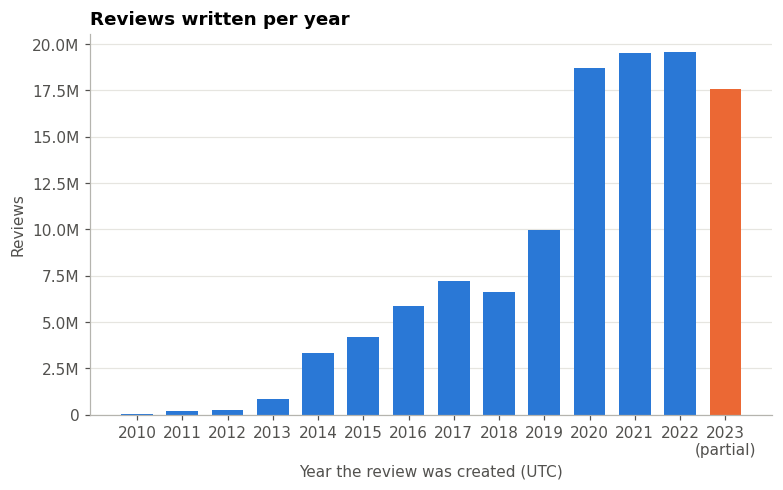

Share of reviews by year: 2010: 0.0%, 2011: 0.2%, 2012: 0.2%, 2013: 0.8%, 2014: 2.9%, 2015: 3.7%, 2016: 5.1%, 2017: 6.4%, 2018: 5.8%, 2019: 8.7%, 2020: 16.4%, 2021: 17.2%, 2022: 17.2%, 2023: 15.4%


In [17]:
def format_count(value):
    """Format a count compactly, e.g. 1234567 becomes '1.2M'.

    Values below 1,000 that are not whole numbers, such as the axis ticks
    of a ratio, keep their decimals instead of being rounded.

    Parameters
    ----------
    value : float
        Count to format.

    Returns
    -------
    str
        The formatted count.
    """
    for divisor, suffix in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(value) >= divisor:
            return f'{value / divisor:.1f}{suffix}'
    if float(value).is_integer():
        return f'{value:,.0f}'
    return f'{value:g}'


def format_value_axis(axis, percent):
    """Show an axis as percentages of 1 or as compact counts.

    Parameters
    ----------
    axis : matplotlib.axis.Axis
        The x or y axis that carries the values.
    percent : bool
        True for shares between 0 and 1, False for counts.
    """
    if percent:
        # Exact labels: a tick at 0.025 reads 2.5%, not a rounded 2%
        axis.set_major_formatter(
            FuncFormatter(lambda value, _: f'{value * 100:g}%'))
    else:
        axis.set_major_formatter(
            FuncFormatter(lambda value, _: format_count(value)))


def plot_bars(labels, values, title, xlabel, ylabel, *, colors=None,
              value_labels=None, reference=None, reference_label=None,
              percent=False):
    """Draw a vertical bar chart for ordered categories, such as years.

    Parameters
    ----------
    labels : sequence of str
        Category labels, left to right.
    values : sequence of float
        Bar heights.
    title, xlabel, ylabel : str
        Title (state the takeaway) and axis labels.
    colors : str or sequence of str, optional
        Bar colors; defaults to the primary color.
    value_labels : sequence of str, optional
        Text printed above each bar.
    reference : float, optional
        Height of a dashed reference line, e.g. the overall share.
    reference_label : str, optional
        Legend entry for the reference line.
    percent : bool
        Format the y-axis as percentages of 1.

    Returns
    -------
    matplotlib.axes.Axes
        The chart, for further annotation.
    """
    positions = np.arange(len(labels))
    values = np.asarray(values, dtype=float)
    _, ax = plt.subplots()
    ax.bar(positions, values, width=0.7,
           color=PRIMARY if colors is None else colors)
    ax.set_xticks(positions, labels)
    if value_labels is not None:
        offset = values.max() * 0.01
        for x, height, text in zip(positions, values, value_labels):
            ax.text(x, height + offset, text, ha='center', va='bottom',
                    fontsize=8, color=MUTED)
        # Room above the tallest bar, so labels stay clear of the title
        top = max(values.max(), reference or 0)
        ax.set_ylim(0, top * 1.15)
    if reference is not None:
        ax.axhline(reference, color=MUTED, linestyle='--', linewidth=1,
                   label=reference_label)
        if reference_label:
            # Above the top-right corner, clear of bars and the title
            ax.legend(loc='lower right', bbox_to_anchor=(1, 1),
                      frameon=False, fontsize=9, borderaxespad=0.2)
    ax.grid(axis='x', visible=False)
    format_value_axis(ax.yaxis, percent)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    return ax


def plot_barh(labels, values, title, xlabel, *, value_labels=None,
              errors=None, reference=None, reference_label=None,
              percent=False, color=PRIMARY):
    """Draw a horizontal bar chart with the first category at the top.

    Parameters
    ----------
    labels : sequence of str
        Category labels, top to bottom.
    values : sequence of float
        Bar lengths.
    title, xlabel : str
        Title (state the takeaway) and x-axis label.
    value_labels : sequence of str, optional
        Text printed at the end of each bar.
    errors : tuple of two sequences, optional
        Lower and upper bounds, drawn as whiskers (e.g. Equation 2).
    reference : float, optional
        Position of a dashed reference line, e.g. the overall share.
    reference_label : str, optional
        Legend entry for the reference line.
    percent : bool
        Format the x-axis as percentages of 1.
    color : str
        Bar color.

    Returns
    -------
    matplotlib.axes.Axes
        The chart, for further annotation.
    """
    values = np.asarray(values, dtype=float)
    positions = np.arange(len(values))[::-1]  # first label at the top
    _, ax = plt.subplots(figsize=(8, max(2.5, 0.36 * len(values) + 1.2)))
    ax.barh(positions, values, height=0.6, color=color)
    ends = values
    if errors is not None:
        lower, upper = (np.asarray(bound, dtype=float) for bound in errors)
        ax.errorbar(values, positions, xerr=[values - lower, upper - values],
                    fmt='none', ecolor=MUTED, elinewidth=1, capsize=3)
        ends = upper
    if value_labels is not None:
        offset = ends.max() * 0.01
        for y, end, text in zip(positions, ends, value_labels):
            ax.text(end + offset, y, text, va='center', fontsize=8,
                    color=MUTED)
        ax.set_xlim(0, ends.max() * 1.15)
    if reference is not None:
        ax.axvline(reference, color=MUTED, linestyle='--', linewidth=1,
                   label=reference_label)
        if reference_label:
            # Above the top-right corner, clear of bars and the title
            ax.legend(loc='lower right', bbox_to_anchor=(1, 1),
                      frameon=False, fontsize=9, borderaxespad=0.2)
    ax.set_yticks(positions, labels)
    ax.grid(axis='y', visible=False)
    format_value_axis(ax.xaxis, percent)
    ax.set(title=title, xlabel=xlabel)
    return ax


# Figure 3: reviews per year, with the final year marked if it is partial
years = reviews_by_year.dropna(subset=['year']).astype({'year': int})
partial_year = (None if last_review is None
                or (last_review.month, last_review.day) == (12, 31)
                else last_review.year)
plot_bars([f'{year}\n(partial)' if year == partial_year else str(year)
           for year in years['year']],
          years['count'],
          title='Reviews written per year',
          xlabel='Year the review was created (UTC)',
          ylabel='Reviews',
          colors=[ACCENT if year == partial_year else PRIMARY
                  for year in years['year']])
plt.show()

# Share of all reviews written in each year (Section 5.5)
print('Share of reviews by year: ' + ', '.join(
    f'{year}: {count / n_raw:.1%}'
    for year, count in zip(years['year'], years['count'])))

**Figure 3.** Number of reviews created in each year, by `timestamp_created` in UTC. The final year, 2023, is partial: the last review was created on 4 November 2023.

Reviews span 2010 to 2023, and their number grew from 27,660 in 2010 to 19,584,959 in 2022. Growth was not steady: the yearly count fell from 7.2 million in 2017 to 6.6 million in 2018, then almost doubled from 9.9 million in 2019 to 18.7 million in 2020. The three most recent complete years, 2020 to 2022, hold 50.8% of all reviews, and together with the partial year 2023 the last four years hold 66.2%, so pooled shares mainly reflect recent reviewing. This has two consequences for RQ2. Years with few reviews give less stable shares, and 2023, which ends on 4 November, must be labeled partial rather than compared as a complete year (Figure 10). The first year is also incomplete, since the first review dates from 16 October 2010. No review lacks a valid creation time, so every review enters the year view.

### 5.6 Games

Distinct appids: 105,893; median reviews per game: 16; largest: 7,704,653
Games with at least 1,000 reviews: 6,699 (6.3% of games), holding 93.9% of reviews
appids with more than one game name: 0


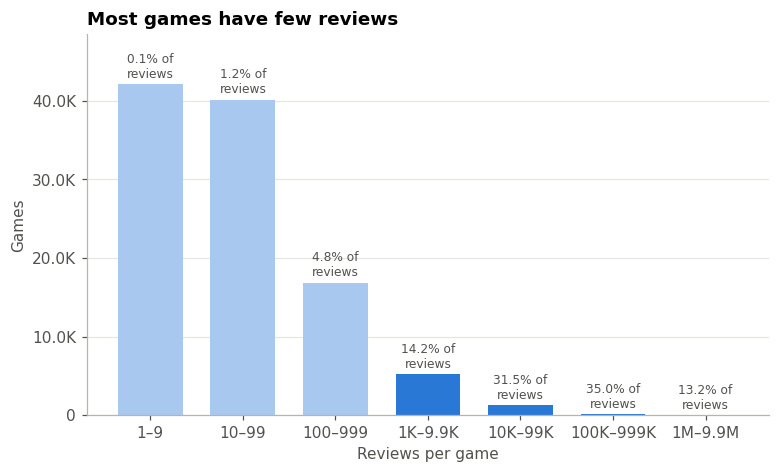

In [18]:
reviews_per_game = (reviews_staged
                    .filter(F.col('appid').isNotNull())
                    .groupBy('appid')
                    .agg(F.count('*').alias('n_reviews'),
                         copies_differ('game').alias('several_names'))
                    .persist())  # reused by the next two queries

game_summary = (reviews_per_game
                .agg(F.count('*').alias('games'),
                     F.percentile_approx('n_reviews', 0.5).alias('median'),
                     F.max('n_reviews').alias('largest'),
                     F.sum((F.col('n_reviews') >= MIN_GAME_REVIEWS)
                           .cast('int')).alias('eligible_games'),
                     F.sum(F.when(F.col('n_reviews') >= MIN_GAME_REVIEWS,
                                  F.col('n_reviews')))
                     .alias('eligible_reviews'),
                     F.sum(F.col('n_reviews')).alias('reviews'),
                     F.sum('several_names').alias('several_names'))
                .first())
print(f'Distinct appids: {game_summary.games:,}; median reviews per game: '
      f'{game_summary.median:,}; largest: {game_summary.largest:,}')
print(f'Games with at least {MIN_GAME_REVIEWS:,} reviews: '
      f'{game_summary.eligible_games:,} '
      f'({game_summary.eligible_games / game_summary.games:.1%} of games), '
      f'holding {game_summary.eligible_reviews / game_summary.reviews:.1%} '
      f'of reviews')
print(f'appids with more than one game name: '
      f'{game_summary.several_names:,}')

# Figure 4: games grouped by order of magnitude of their review count
SIZE_LABELS = {0: '1–9', 1: '10–99', 2: '100–999', 3: '1K–9.9K',
               4: '10K–99K', 5: '100K–999K', 6: '1M–9.9M'}
size_bins = (reviews_per_game
             .groupBy(F.floor(F.log10('n_reviews')).alias('magnitude'))
             .agg(F.count('*').alias('games'),
                  F.sum('n_reviews').alias('reviews'))
             .toPandas()
             .sort_values('magnitude'))
reviews_per_game.unpersist()
size_bins['review share'] = size_bins['reviews'] / size_bins['reviews'].sum()
eligible_bin = size_bins['magnitude'] >= np.log10(MIN_GAME_REVIEWS)
plot_bars([SIZE_LABELS.get(m, f'1e{m}+') for m in size_bins['magnitude']],
          size_bins['games'],
          title='Most games have few reviews',
          xlabel='Reviews per game',
          ylabel='Games',
          colors=[PRIMARY if eligible else '#a9c8ef'
                  for eligible in eligible_bin],
          value_labels=[f'{share:.1%} of\nreviews'
                        for share in size_bins['review share']])
plt.show()

**Figure 4.** Number of games by how many reviews they have, in powers of ten. The label above each bar is the share of all reviews held by those games. Darker bars are the games with at least 1,000 reviews, which RQ1 ranks.

The 105,893 games differ enormously in how many reviews they receive. The median game has 16 reviews, while the most reviewed game has 7,704,653. About three-quarters of the games have fewer than 100 reviews, and together they hold only 1.3% of all reviews. Only 6,699 games (6.3%) reach the 1,000 reviews that RQ1 requires, yet they hold 93.9% of all reviews (Figure 4). Two decisions follow from this. First, the 1,000-review threshold excludes most games but keeps most reviews, and it prevents games with a handful of reviews from topping the RQ1 ranking (Table 3). Second, pooled shares in RQ2 are dominated by the most reviewed games, which is why Section 8.4 also reports game-averaged shares. No appid appears with more than one game name, so each name is a consistent label. The report nevertheless identifies games by `appid`, Steam's own key, and uses the name only as a label (Section 7.1).

### 5.7 Languages

Distinct languages: 29


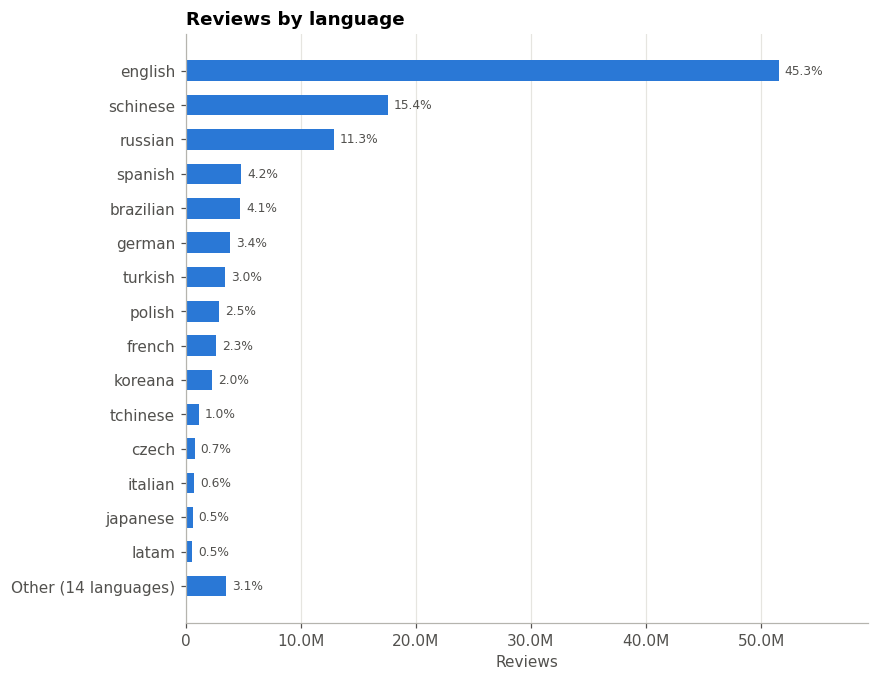

In [19]:
# Reviews per language, most common first
language_counts = (reviews_staged.groupBy('language').count()
                   .toPandas()
                   .fillna({'language': '(missing)'})
                   .sort_values('count', ascending=False))
# Show the 15 largest languages and combine the rest into one bar
SHOWN_LANGUAGES = 15
shown = language_counts.head(SHOWN_LANGUAGES)
other_count = language_counts['count'].iloc[SHOWN_LANGUAGES:].sum()
n_other = len(language_counts) - SHOWN_LANGUAGES
labels = list(shown['language'])
counts = list(shown['count'])
if n_other > 0:
    labels.append(f'Other ({n_other} languages)')
    counts.append(other_count)
print(f'Distinct languages: {len(language_counts)}')

# Figure 5, labeled with each language's share of all reviews
plot_barh(labels, counts,
          title='Reviews by language',
          xlabel='Reviews',
          value_labels=[f'{count / n_raw:.1%}' for count in counts])
plt.show()

**Figure 5.** Number of reviews in the 15 most common languages, with the remaining languages combined; labels give each language's share of all reviews. Language names are Steam's codes (for example, `schinese` is Simplified Chinese).

Reviews are written in 29 languages but concentrate in a few. English accounts for 45.3% of reviews, followed by Simplified Chinese (15.4%) and Russian (11.3%); no other language exceeds 5% (Figure 5). The 10 most common languages, which RQ2 compares, cover 93.6% of retained reviews (Section 8.3), and the 14 least common languages together hold 3.1%. The language is the one the reviewer chose for the review (Table 2), so it describes the review and not necessarily the reviewer's country. Because RQ3 analyzes English reviews only, its findings describe 45.3% of the data.

### 5.8 Playtime at Review

Known playtime: 113,883,717 reviews; missing: 0; zero: 1,871,268; negative: 0
10th percentile: 1.1 h
25th percentile: 4.5 h
50th percentile: 15.3 h
75th percentile: 61.5 h
90th percentile: 254.8 h
99th percentile: 1,736.1 h


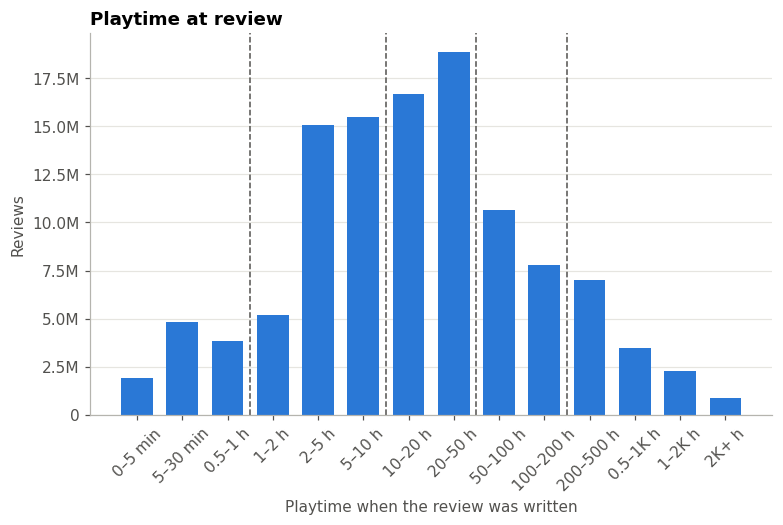

Share of known playtimes per band: Under 1 h: 9.2%, 1–10 h: 31.4%, 10–50 h: 31.2%, 50–200 h: 16.2%, 200+ h: 11.9%


In [20]:
playtime_hours = (F.col('author_playtime_at_review') / 60).alias('hours')
playtime_stats = (reviews_staged.select(playtime_hours)
                  .agg(F.count('hours').alias('known'),
                       F.sum((F.col('hours') == 0).cast('int'))
                       .alias('zero'),
                       F.sum((F.col('hours') < 0).cast('int'))
                       .alias('negative'),
                       F.percentile_approx(
                           'hours', [0.1, 0.25, 0.5, 0.75, 0.9, 0.99])
                       .alias('quantiles'))
                  .first())
print(f'Known playtime: {playtime_stats.known:,} reviews; '
      f'missing: {n_raw - playtime_stats.known:,}; '
      f'zero: {playtime_stats.zero:,}; negative: {playtime_stats.negative:,}')
for level, hours in zip(['10th', '25th', '50th', '75th', '90th', '99th'],
                        playtime_stats.quantiles or []):
    print(f'{level} percentile: {hours:,.1f} h')

# Figure 6: histogram on a log-like scale; edges include the band limits
PLAYTIME_SPLITS = [-float('inf'), 0, 5 / 60, 0.5, 1, 2, 5, 10, 20, 50, 100,
                   200, 500, 1_000, 2_000, float('inf')]
PLAYTIME_BIN_LABELS = ['< 0', '0–5 min', '5–30 min', '0.5–1 h', '1–2 h',
                       '2–5 h', '5–10 h', '10–20 h', '20–50 h', '50–100 h',
                       '100–200 h', '200–500 h', '0.5–1K h', '1–2K h',
                       '2K+ h']
# handleInvalid='skip' drops NaN values instead of stopping the job
bucketizer = Bucketizer(splits=PLAYTIME_SPLITS, inputCol='hours',
                        outputCol='bin', handleInvalid='skip')
playtime_bins = (bucketizer
                 .transform(reviews_staged.select(playtime_hours).dropna())
                 .groupBy('bin').count()
                 .toPandas()
                 .set_index('bin')['count']
                 .reindex(range(len(PLAYTIME_BIN_LABELS)), fill_value=0))
if playtime_bins.iloc[0] == 0:  # show the '< 0' bin only if it is used
    playtime_bins = playtime_bins.iloc[1:]
bin_labels = [PLAYTIME_BIN_LABELS[int(i)] for i in playtime_bins.index]
ax = plot_bars(bin_labels, playtime_bins.values,
               title='Playtime at review',
               xlabel='Playtime when the review was written',
               ylabel='Reviews')
ax.tick_params(axis='x', labelrotation=45)
# Dashed lines at the band limits of Section 3.2
for edge in (1, 10, 50, 200):
    first_bin = PLAYTIME_SPLITS.index(edge)
    ax.axvline(list(playtime_bins.index).index(first_bin) - 0.5,
               color=MUTED, linestyle='--', linewidth=1)
plt.show()

# Share of reviews with known playtime in each RQ2 band (Section 3.2);
# the histogram bins nest inside the bands, so their counts add up
known_playtime = playtime_bins.sum()
upper_bounds = [lower for lower, _ in PLAYTIME_BANDS[1:]] + [float('inf')]
band_shares = []
for (lower, label), upper in zip(PLAYTIME_BANDS, upper_bounds):
    in_band = [i for i in playtime_bins.index
               if lower <= PLAYTIME_SPLITS[int(i)] < upper]
    band_shares.append(
        f'{label}: {playtime_bins[in_band].sum() / known_playtime:.1%}')
print('Share of known playtimes per band: ' + ', '.join(band_shares))

**Figure 6.** Number of reviews by playtime at review (minutes converted to hours), on bins that widen with playtime. Dashed lines mark the limits of the playtime bands used in RQ2 (1, 10, 50, and 200 hours). No review has missing playtime.

Playtime at review is known for all 113,883,717 reviews (100%). It is strongly right-skewed. The median reviewer had played 15.3 hours when writing, while 10% had played more than 254.8 hours, and the 99th percentile is 1,736.1 hours. A median in hours rather than in thousands confirms that the column is recorded in minutes, as documented (Valve Corporation, n.d.-a). 1,871,268 reviews (1.6%) record a playtime of exactly zero. They form a spike of their own: the 0–5 min bin of Figure 6 holds hardly any other reviews. A zero may mean very short play or time that the Steam client did not track (Section 2.3), and the data cannot tell the two apart. These reviews are kept in the under-1-hour band, where they make up about 18% of the reviews, and Section 12.2 lists this as a limitation. No review records a negative playtime. The five RQ2 bands, from under 1 hour to 200+ hours, hold 9.2%, 31.4%, 31.2%, 16.2%, and 11.9% of the reviews (printed below the figure), so every band is large enough for a stable share. Because no playtime is missing, the *Unknown* band defined in Section 3.2 is empty.

### 5.9 Review Text

In [21]:
# Review length and English word counts in one pass over the table
text_stats = (reviews_staged
              .agg(F.count('review_length').alias('with_text'),
                   F.percentile_approx('review_length', [0.5, 0.9, 0.99])
                   .alias('length_quantiles'),
                   F.max('review_length').alias('longest'),
                   F.sum((F.col('language') == 'english').cast('int'))
                   .alias('english'),
                   F.count('words').alias('english_with_words'),
                   F.mean(F.when(F.col('words').isNotNull(),
                                 F.size('words'))).alias('mean_words'))
              .first())
median_length, p90_length, p99_length = text_stats.length_quantiles
print(f'Reviews with text: {text_stats.with_text:,} '
      f'({text_stats.with_text / n_raw:.2%}); '
      f'empty or missing: {n_raw - text_stats.with_text:,}')
print(f'Length in characters: median {median_length:,}, '
      f'90th percentile {p90_length:,}, 99th percentile {p99_length:,}, '
      f'longest {text_stats.longest:,}')
print(f'English reviews: {text_stats.english:,}; with at least one content '
      f'word: {text_stats.english_with_words:,}; mean distinct content '
      f'words per review: {text_stats.mean_words:.1f}')

Reviews with text: 113,883,717 (100.00%); empty or missing: 0
Length in characters: median 40, 90th percentile 429, 99th percentile 2,336, longest 9,801,289
English reviews: 51,544,612; with at least one content word: 50,131,002; mean distinct content words per review: 18.8


None of the 113,883,717 reviews has empty text: every review has at least one character, so every review can in principle enter RQ3. Reviews are short: the median review has 40 characters, and 90% have fewer than 429. A few are extremely long, with the 99th percentile at 2,336 characters and the longest at 9,801,289. A review of almost ten million characters is implausible as typed text and may contain repeated characters or a formatting problem in the source. It does not affect RQ1 or RQ2, and in RQ3 it counts only once, through its set of distinct words (Section 9.1). Of the 51,544,612 English reviews, 50,131,002 (97.3%) keep at least one content word after tokenization, with 18.8 distinct content words on average. These reviews form the base of RQ3 (Section 9.1).

### 5.10 Other Columns

The remaining columns are not used in the analysis, but they are part of the raw data, so Tables 7 and 9 summarize them as well. The reviewer-activity columns show a median of 1 game owned and 6 reviews written, against means of 128 games and 26.8 reviews. The low median of games owned suggests that this field is often incomplete, possibly for reviewers whose game library is private. `author_playtime_forever`, `author_playtime_last_two_weeks`, and `author_last_played` describe the reviewer at the time of collection, not when the review was written, so they cannot describe the circumstances of the recommendation. The helpfulness columns (`votes_up`, `votes_funny`, `weighted_vote_score`, and `comment_count`) measure how other users reacted to a review. The two Steam China columns carry little information: `hidden_in_steam_china` is true for 22.22% of reviews, and `steam_china_location` is filled in only 1,022 rows. Neither plays a role in this report.

### 5.11 Key Takeaways from the Exploration

- **The file is read correctly.** No numeric value failed to convert (Table 7), and the record count matches the game plan only when `multiLine` is used (Table 6).
- **Few rows need cleaning.** No row has a missing or invalid key field (Table 7), and 0.310% of rows are extra copies of a review ID, listed under a second or third game (Table 8). Section 6 investigates and removes them.
- **Negative recommendations are a minority.** 14.41% of raw reviews do not recommend the game (Section 5.4). This is the baseline against which every share in Sections 7 and 8 is compared.
- **Reviews concentrate in recent years and in few games.** 66.2% of reviews were written from 2020 to 2023 (Figure 3), and the 6,699 games with at least 1,000 reviews hold 93.9% of all reviews (Figure 4). This motivates the 1,000-review threshold and the game-averaged check in Section 8.4.
- **The final year is partial.** The data ends on 4 November 2023, so 2023 is labeled partial in Figures 3 and 10.
- **English dominates.** English reviews make up 45.3% of the data (Figure 5). That is enough for a robust RQ3, but it covers one language community only.
- **Playtime is skewed but complete.** Every review records its playtime at review; the median is 15.3 hours, while the top 1% exceed 1,736 hours (Figure 6). All reviews therefore enter the five playtime bands of RQ2, and the *Unknown* band stays empty.

<a id="cleaning"></a>
## 6. Data Cleaning and Filtering

This section turns the staged rows into the analysis table used in Sections 7 to 9. It first investigates why values are missing or invalid (Section 6.1) and then decides how to handle each column (Section 6.2). Only after that does it filter the data, reporting the number and share of rows kept after each step (Section 6.3).

### 6.1 Why Values Are Missing or Invalid

Table 7 found no missing or invalid values in the key fields, and only three small gaps elsewhere: 5,201 missing game names, 8 rows without the playtime fields recorded at collection time, and the almost empty `steam_china_location`. Two checks test where missing values come from and whether any problem is hidden in the rows. The first asks whether missing playtime at review is concentrated in particular years. That would point to a change in what Steam recorded, rather than to random gaps or to problems in reading the file.

In [22]:
def missing_share_by(df, column, group):
    """Share of rows where a column is missing, for each group.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        Table to examine.
    column : str
        Column whose missing values are counted.
    group : str
        Column that defines the groups, e.g. the review year.

    Returns
    -------
    pandas.DataFrame
        Rows, missing rows, and the missing share for each group.
    """
    return (df.groupBy(group)
            .agg(F.count('*').alias('rows'),
                 F.sum(F.col(column).isNull().cast('int')).alias('missing'))
            .withColumn('missing share', F.col('missing') / F.col('rows'))
            .toPandas()
            .sort_values(group))


staged_with_year = reviews_staged.withColumn(
    'review_year', F.year(F.timestamp_seconds('timestamp_created')))
missing_playtime = missing_share_by(staged_with_year,
                                    'author_playtime_at_review',
                                    'review_year')
display(missing_playtime.set_index('review_year').style.format(
    {'rows': '{:,.0f}', 'missing': '{:,.0f}', 'missing share': '{:.2%}'}))

,rows,missing,missing share
review_year,,,
2010,"27,660",0,0.00%
2011,"184,975",0,0.00%
2012,"259,316",0,0.00%
2013,"859,723",0,0.00%
2014,"3,320,899",0,0.00%
2015,"4,186,116",0,0.00%
2016,"5,848,401",0,0.00%
2017,"7,240,334",0,0.00%
2018,"6,599,615",0,0.00%


**Table 10.** Reviews with missing playtime at review, by the year in which the review was created.

Table 10 shows that playtime at review is filled in for every review in every year, from the 27,660 reviews of 2010 to the 17,578,904 of 2023: the missing share is 0.00% throughout. The field is therefore present even for the oldest reviews in the snapshot, and the playtime view of RQ2 covers all years equally. No review needs the *Unknown* band, and no year is under-represented in the playtime analysis.

The second check asks whether rows with a missing key field are broken records or genuine reviews with a single gap. If a row was misread, many of its fields are missing at once. If a single value is missing, the rest of the row is complete.

In [23]:
# Fields of the staged table that can be missing
STAGED_FIELDS = list(NUMERIC_TYPES) + TEXT_COLUMNS + ['review_length']
n_missing_fields = sum(F.col(name).isNull().cast('int')
                       for name in STAGED_FIELDS)

# Rows with each kind of problem, compared with all rows
PROBLEM_GROUPS = {
    'All rows': F.lit(True),
    'Missing or invalid recommendationid':
        F.col('recommendationid').isNull(),
    'Missing or invalid appid': F.col('appid').isNull(),
    'Missing or unrecognized voted_up': to_bool('voted_up').isNull(),
    'At least one failed cast': F.size('cast_failures') > 0,
}
aggregations = []
for index, condition in enumerate(PROBLEM_GROUPS.values()):
    aggregations += [
        F.sum(condition.cast('int')).alias(f'rows_{index}'),
        F.avg(F.when(condition, n_missing_fields)).alias(f'fields_{index}'),
    ]
problem_stats = reviews_staged.agg(*aggregations).first()

problem_rows = pd.DataFrame({
    'rows': [problem_stats[f'rows_{i}'] or 0
             for i in range(len(PROBLEM_GROUPS))],
    'mean missing fields': [problem_stats[f'fields_{i}']
                            for i in range(len(PROBLEM_GROUPS))],
}, index=list(PROBLEM_GROUPS))
problem_rows.insert(1, '% of raw rows', problem_rows['rows'] / n_raw)
display(problem_rows.style.format({'rows': '{:,.0f}', '% of raw rows':
                                   '{:.3%}', 'mean missing fields': '{:.1f}'},
                                  na_rep='–'))

,rows,% of raw rows,mean missing fields
All rows,"113,883,717",100.000%,1.0
Missing or invalid recommendationid,0,0.000%,–
Missing or invalid appid,0,0.000%,–
Missing or unrecognized voted_up,0,0.000%,–
At least one failed cast,0,0.000%,–


**Table 11.** Rows with a missing or invalid key field, compared with all rows: how many there are and how many of the 23 staged fields are missing in them on average.

An ordinary row misses 1.0 of the 23 staged fields on average, almost always `steam_china_location`, which is empty in all but 1,022 rows (Table 7). No row has a missing or invalid `recommendationid` or `appid`, a missing or unrecognized `voted_up`, or a failed cast, so the problem groups of Table 11 are empty and their mean is shown as "–". There are therefore no broken records in the staged table: every row can be identified, assigned to a game, and classified as positive or negative. The only gaps in fields that the analysis uses are the 5,201 missing game names, and these rows keep their `appid`, which identifies the game.

### 6.2 Handling of Missing and Invalid Values

Table 12 states how each column with possible missing or invalid values is handled. Each decision follows from the evidence in Section 6.1 and the role of the column in the analysis (Table 2). Because most of these columns turned out to be complete, most rules remove or relabel no rows in this snapshot; they are kept so that the pipeline handles a newer snapshot correctly. No value is imputed: every field used in the analysis is a fact recorded by Steam, and an imputed recommendation, game, or playtime would be invented data.

**Table 12.** How each column with possible missing or invalid values is handled, and why.

| Column | Missing or invalid rows (%) | Why (Section 6.1) | Handling | Justification |
|---|---|---|---|---|
| `recommendationid` | 0 (0.00%) | None found (Table 11) | Drop the row (none dropped) | A review that cannot be identified cannot be de-duplicated. |
| `appid` | 0 (0.00%) | None found (Table 11) | Drop the row (none dropped) | The game is the unit of RQ1, and imputing it would invent data. |
| `voted_up` | 0 (0.00%) | None found; always `1` or `0` (Table 9) | Drop the row (none dropped) | The recommendation is the outcome of every research question; imputing it would assume the answer. |
| `author_playtime_at_review` | 0 (0.00%) | None found in any year (Table 10) | Keep the row; assign the *Unknown* band (none assigned) | Game rankings do not need playtime, and dropping such reviews could remove some years selectively. Negative playtimes, which are impossible, would also be treated as unknown; none occur (Section 5.8). |
| `timestamp_created` | 0 (0.00%) | None found (Section 5.5) | Keep the row; leave it out of the year view only | Only the year view of RQ2 needs the creation time. |
| `language` | 0 (0.00%) | None found (Table 7) | Keep the row; label it *unknown* | Only RQ2 and RQ3 need the language. |
| `game` | 5,201 (0.005%) | Name not supplied by the dataset author for these rows (Section 2.1) | Keep the row; the `appid` still identifies the game | `appid` identifies the game; the name is only a label. |
| `review` (empty text) | 0 (0.00%) | None found (Section 5.9) | Keep the row; leave it out of RQ3 only | An empty review still carries a recommendation. |
| `author_playtime_forever`, `author_playtime_last_two_weeks`, `author_last_played` | 8 each (0.00%) | Not filled for these 8 rows; too few to affect any statistic | No handling | They are not used in the analysis. |
| `steam_china_location` | 113,882,695 (99.999%) | Filled only for a few reviews; the documentation does not describe it (Table 2) | No handling | It is not used in the analysis. |
| Other columns | See Table 7 | – | No handling | They are not used in the analysis. |

### 6.3 Filtering Steps

The four review-level filters below are applied in order, and Table 13 reports the rows remaining after each. Counting the rows after de-duplication requires a window over all review IDs. To keep this cheap, the counts use only the four columns the filters need; the full table is written once, in Section 6.4.

In [24]:
def keep_latest_copy(df):
    """Keep one row per review ID: its most recently updated copy.

    Ties are broken by appid and the raw flag, so the result does not
    depend on how Spark orders the rows.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        Rows with a non-null ``recommendationid``.

    Returns
    -------
    pyspark.sql.DataFrame
        One row per ``recommendationid``.
    """
    latest_first = (Window.partitionBy('recommendationid')
                    .orderBy(F.col('timestamp_updated').desc_nulls_last(),
                             F.col('appid').asc_nulls_last(),
                             F.col('voted_up').asc_nulls_last()))
    return (df.withColumn('copy_rank', F.row_number().over(latest_first))
            .filter(F.col('copy_rank') == 1)
            .drop('copy_rank'))


valid_ids = reviews_staged.filter(F.col('recommendationid').isNotNull())

# Count the rows left after each step. The de-duplication is run on four
# small columns only, so the counts are cheap.
with timed('Count rows after each filtering step'):
    n_valid_id = valid_ids.count()
    latest = keep_latest_copy(valid_ids.select(
        'recommendationid', 'timestamp_updated', 'appid', 'voted_up'))
    step_counts = (latest
                   .withColumn('recommended', to_bool('voted_up'))
                   .agg(F.count('*').alias('unique'),
                        F.count('appid').alias('with_appid'),
                        F.sum((F.col('appid').isNotNull()
                               & F.col('recommended').isNotNull())
                              .cast('int')).alias('with_flag'))
                   .first())

FILTER_STEPS = [
    ('Raw reviews', n_raw),
    ('1. Valid review ID', n_valid_id),
    ('2. One row per review ID (latest update)', step_counts.unique),
    ('3. Valid appid', step_counts.with_appid),
    ('4. Recognized recommendation flag', step_counts.with_flag or 0),
]
filter_log = pd.DataFrame(FILTER_STEPS, columns=['step', 'rows remaining'])
filter_log['rows removed'] = (filter_log['rows remaining'].shift(1)
                              - filter_log['rows remaining']).fillna(0)
filter_log['% removed in step'] = (filter_log['rows removed']
                                   / filter_log['rows remaining'].shift(1))
filter_log['% of raw remaining'] = filter_log['rows remaining'] / n_raw
display(filter_log.set_index('step').style.format({
    'rows remaining': '{:,.0f}', 'rows removed': '{:,.0f}',
    '% removed in step': '{:.3%}', '% of raw remaining': '{:.3%}',
}, na_rep='–'))

Count rows after each filtering step: 1.7 min


,rows remaining,rows removed,% removed in step,% of raw remaining
step,,,,
Raw reviews,"113,883,717",0,–,100.000%
1. Valid review ID,"113,883,717",0,0.000%,100.000%
2. One row per review ID (latest update),"113,530,421","353,296",0.310%,99.690%
3. Valid appid,"113,530,421",0,0.000%,99.690%
4. Recognized recommendation flag,"113,530,421",0,0.000%,99.690%


**Table 13.** Review-level filtering steps, in order, with the rows remaining and removed after each step, the share removed by the step, and the share of the raw reviews that remains.

1. **Valid review ID.** The first step removes 0 rows (0.000%), because every `recommendationid` is present and numeric. The step stays in the pipeline because, without an ID, a review cannot be told apart from its copies.
2. **One row per review ID.** The second step removes 353,296 rows (0.310%), the extra copies of the 332,865 review IDs that appear more than once (Table 8). For each ID, the row with the latest `timestamp_updated` is kept, with ties broken by the lowest `appid` and then the raw flag, so that the result does not depend on how Spark orders rows. Because the copies almost always differ only in `appid`, this assigns each such review to the game with the lowest `appid`. Unlike `dropDuplicates()`, which keeps an arbitrary copy, this rule is deterministic and keeps the reviewer's latest version where versions differ.
3. **Valid game ID.** The third step removes 0 rows (0.000%): every remaining row has a valid `appid` and can be assigned to a game.
4. **Recognized recommendation flag.** The last step removes 0 rows (0.000%): every remaining `voted_up` is `1` or `0`, so every review carries an outcome.

In total, the four steps remove 353,296 rows, or 0.310% of the raw data, and keep 113,530,421 reviews (99.690%). Removing the duplicates changes the overall negative share only from 14.412% to 14.407% (Sections 5.4 and 6.4), so the cleaning cannot materially change any share reported in Sections 7 to 9. It matters mainly for game-level counts, since each duplicated review now counts under one game only (Section 7.2). Two further filters apply only to specific research questions and are reported where they are used: games with at least 1,000 reviews for RQ1 (Section 7.2), and English reviews with at least one content word for RQ3 (Section 9.1).

### 6.4 The Analysis Table

The analysis table keeps one row per retained review and only the columns that Sections 7 to 9 use, with the definitions of Section 3.2 and the handling of Section 6.2 applied:

- `review_id` and `appid` identify the review and the game; `game` is the name label.
- `recommended` is the converted flag, and `is_negative` is 1 for a negative recommendation and 0 otherwise, so that its mean is the negative share of Equation 1.
- `language` uses *unknown* for missing values, and `created_at` is the UTC creation time.
- `playtime_hours` converts minutes to hours, and `playtime_band` assigns the bands of Section 3.2, with *Unknown* for missing or negative values (none occur).
- `review_length` and `words` carry the review-text measures from staging.

The table is written to the scratch folder and registered as the SQL view `reviews`, which Sections 7 and 9 query.

In [25]:
def playtime_band(minutes_column):
    """Assign the playtime-at-review band of Section 3.2.

    Parameters
    ----------
    minutes_column : str
        Column with the playtime at review in minutes.

    Returns
    -------
    pyspark.sql.Column
        Band label; missing or negative playtimes are 'Unknown'.
    """
    hours = F.col(minutes_column) / 60
    band = F.when(hours.isNull() | (hours < 0), F.lit(UNKNOWN_BAND))
    for lower_bound, label in reversed(PLAYTIME_BANDS):
        band = band.when(hours >= lower_bound, F.lit(label))
    return band


reviews_clean = (
    keep_latest_copy(valid_ids)
    .withColumn('recommended', to_bool('voted_up'))
    .filter(F.col('appid').isNotNull() & F.col('recommended').isNotNull())
    .select(
        F.col('recommendationid').alias('review_id'),
        'appid',
        'game',
        'recommended',
        (~F.col('recommended')).cast('int').alias('is_negative'),
        F.coalesce('language', F.lit('unknown')).alias('language'),
        F.timestamp_seconds('timestamp_created').alias('created_at'),
        (F.col('author_playtime_at_review') / 60).alias('playtime_hours'),
        playtime_band('author_playtime_at_review').alias('playtime_band'),
        'review_length',
        'words',
    )
)
with timed('Write the cleaned analysis table'):
    reviews_clean.write.parquet(CLEAN_PATH, mode='overwrite')

reviews = spark.read.parquet(CLEAN_PATH)
reviews.createOrReplaceTempView('reviews')  # for the SQL queries below
n_clean = reviews.count()
assert n_clean == filter_log['rows remaining'].iloc[-1]
overall_share = reviews.agg(F.avg('is_negative')).first()[0]
print(f'Retained reviews: {n_clean:,} ({n_clean / n_raw:.2%} of raw); '
      f'overall negative share s = {overall_share:.2%}')
reviews.printSchema()

Write the cleaned analysis table: 14.0 min
Retained reviews: 113,530,421 (99.69% of raw); overall negative share s = 14.41%
root
 |-- review_id: long (nullable = true)
 |-- appid: long (nullable = true)
 |-- game: string (nullable = true)
 |-- recommended: boolean (nullable = true)
 |-- is_negative: integer (nullable = true)
 |-- language: string (nullable = true)
 |-- created_at: timestamp (nullable = true)
 |-- playtime_hours: double (nullable = true)
 |-- playtime_band: string (nullable = true)
 |-- review_length: integer (nullable = true)
 |-- words: array (nullable = true)
 |    |-- element: string (containsNull = true)



The analysis table holds 113,530,421 reviews, 99.69% of the raw rows, the same number as the last row of Table 13 (the cell checks this with an assertion). Across all retained reviews, the overall negative share is $s$ = 14.41% (Equation 1), practically the same as the raw share of Section 5.4. This value is the reference line in Figures 7 and 9 to 11: a game or reviewer group above it is more critical than the average review.

<a id="rq1"></a>
## 7. Games with the Highest Share of Negative Recommendations (RQ1)

This section answers RQ1. Section 7.1 computes the negative share (Equation 1) of every game in Spark, Section 7.2 sets aside games with fewer than 1,000 retained reviews, and the remaining games are ranked by share (Section 7.3) and by number of negative reviews (Section 7.4). Section 7.5 checks how much the ranking depends on these choices. The results describe which games draw negative recommendations; they do not establish why.

### 7.1 Negative Share of Each Game

Each game's share is computed with the Spark SQL API on the `reviews` view (lecture: *Spark SQL API*). The result has one row per game, small enough to move to pandas, where the 95% Wilson interval of each share (Equation 2) is added.

In [26]:
GAME_STATS_SQL = """
SELECT
    appid,
    MAX(game) AS game,               -- one label per appid (Section 5.6)
    COUNT(*) AS n_reviews,
    SUM(is_negative) AS n_negative,
    AVG(is_negative) AS negative_share
FROM reviews
GROUP BY appid
"""
with timed('Aggregate reviews per game'):
    game_stats = spark.sql(GAME_STATS_SQL).toPandas()
game_stats['game'] = game_stats['game'].fillna(
    'appid ' + game_stats['appid'].astype(str))


def wilson_interval(negatives, totals, z=1.96):
    """Wilson score interval for a share (Equation 2; Wilson, 1927).

    Parameters
    ----------
    negatives : array-like
        Number of negative reviews in each group.
    totals : array-like
        Number of reviews in each group.
    z : float
        Normal quantile; 1.96 gives a 95% interval.

    Returns
    -------
    tuple of numpy.ndarray
        Lower and upper bounds of the interval.
    """
    negatives = np.asarray(negatives, dtype=float)
    totals = np.asarray(totals, dtype=float)
    share = negatives / totals
    denominator = 1 + z ** 2 / totals
    centre = (share + z ** 2 / (2 * totals)) / denominator
    half_width = z * np.sqrt(share * (1 - share) / totals
                             + z ** 2 / (4 * totals ** 2)) / denominator
    return centre - half_width, centre + half_width


game_stats['ci_lower'], game_stats['ci_upper'] = wilson_interval(
    game_stats['n_negative'], game_stats['n_reviews'])
print(f'Games: {len(game_stats):,}')

Aggregate reviews per game: 1.2 min
Games: 105,864


### 7.2 Games with Enough Reviews

A share computed from a handful of reviews can reach 100% by chance, so games with fewer than 1,000 retained reviews are left out of the ranking (Table 3). Their reviews stay in Sections 8 and 9. At 1,000 reviews, the 95% Wilson interval (Equation 2) is at most about ±3.1 percentage points wide, which is reached at a share of 50% (printed below); this is narrow enough to separate games whose shares differ by several points. The cell below reports the number and proportion of games, and of retained reviews, that pass the threshold.

In [27]:
eligible = game_stats['n_reviews'] >= MIN_GAME_REVIEWS
eligible_reviews = game_stats.loc[eligible, 'n_reviews'].sum()
print(f'Games with at least {MIN_GAME_REVIEWS:,} retained reviews: '
      f'{eligible.sum():,} of {len(game_stats):,} '
      f'({eligible.mean():.2%} of games)')
print(f'Reviews in those games: {eligible_reviews:,} of {n_clean:,} '
      f'({eligible_reviews / n_clean:.2%})')

# Widest possible 95% interval at the threshold (share of 50%)
widest_lower, widest_upper = wilson_interval(MIN_GAME_REVIEWS / 2,
                                             MIN_GAME_REVIEWS)
print(f'Widest 95% interval at {MIN_GAME_REVIEWS:,} reviews: '
      f'±{(widest_upper - widest_lower) / 2 * 100:.1f} percentage points')

Games with at least 1,000 retained reviews: 6,682 of 105,864 (6.31% of games)
Reviews in those games: 106,567,194 of 113,530,421 (93.87%)
Widest 95% interval at 1,000 reviews: ±3.1 percentage points


6,682 of the 105,864 games (6.31%) have at least 1,000 retained reviews, but they hold 106,567,194 of the 113,530,421 retained reviews (93.87%). The ranking therefore excludes most games but covers most reviews, as the long tail of Figure 4 suggested. Both counts are slightly lower than before cleaning (6,699 of 105,893 games, Section 5.6), because removing the duplicate copies (Section 6.3) takes reviews away from the games with the higher `appid`. Twenty-nine appids lose all their reviews in this way, which supports the reading of Section 5.3 that some products only list reviews shared with another appid.

### 7.3 Highest Shares of Negative Recommendations

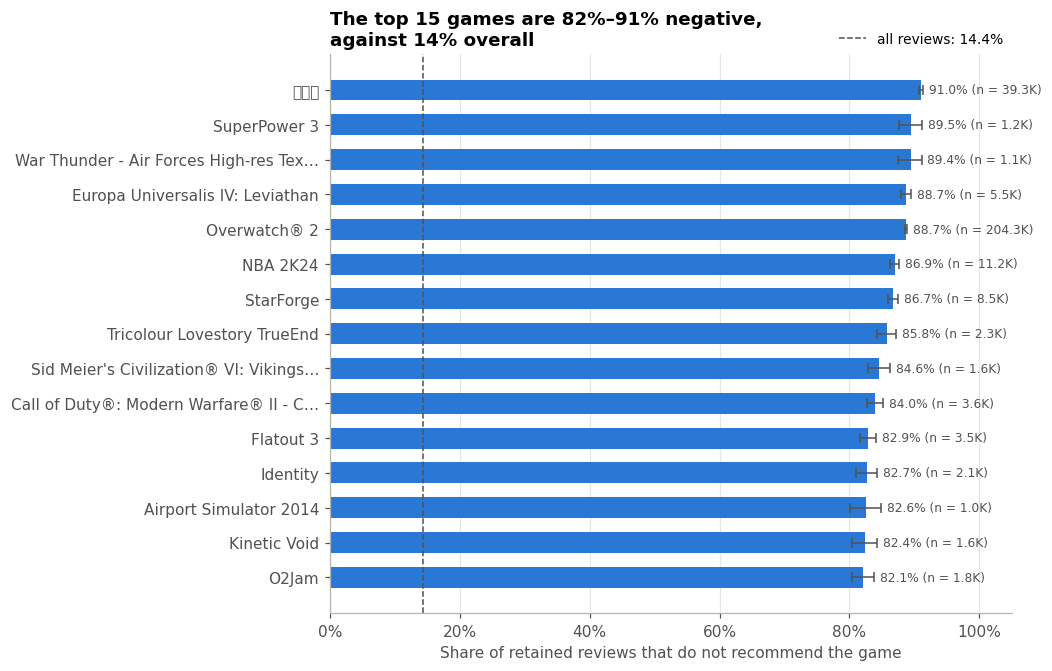

In [28]:
def top_games(stats, min_reviews, n, rank_by='negative_share'):
    """Rank the games that have enough reviews, highest value first.

    Parameters
    ----------
    stats : pandas.DataFrame
        One row per game, as in ``game_stats``.
    min_reviews : int
        Minimum number of retained reviews.
    n : int
        Number of games to return.
    rank_by : str
        Column to rank by; ties go to the game with more reviews.

    Returns
    -------
    pandas.DataFrame
        The top ``n`` games.
    """
    return (stats[stats['n_reviews'] >= min_reviews]
            .sort_values([rank_by, 'n_reviews'], ascending=False)
            .head(n))


def shorten(name, width=38):
    """Shorten a long name for use as an axis label.

    Parameters
    ----------
    name : str
        Name to shorten.
    width : int
        Maximum number of characters.

    Returns
    -------
    str
        The name, cut with an ellipsis if it is too long.
    """
    name = str(name)
    return name if len(name) <= width else name[:width - 1] + '…'


top_by_share = top_games(game_stats, MIN_GAME_REVIEWS, TOP_GAMES_BY_SHARE)
lowest_top_share = top_by_share['negative_share'].min()
highest_top_share = top_by_share['negative_share'].max()
plot_barh([shorten(name) for name in top_by_share['game']],
          top_by_share['negative_share'],
          title=f'The top {len(top_by_share)} games are '
                f'{lowest_top_share:.0%}–{highest_top_share:.0%} negative,\n'
                f'against {overall_share:.0%} overall',
          xlabel='Share of retained reviews that do not recommend the game',
          value_labels=[f'{share:.1%} (n = {format_count(n)})'
                        for share, n in zip(top_by_share['negative_share'],
                                            top_by_share['n_reviews'])],
          errors=(top_by_share['ci_lower'], top_by_share['ci_upper']),
          reference=overall_share,
          reference_label=f'all reviews: {overall_share:.1%}',
          percent=True)
plt.show()

**Figure 7.** The 15 games with at least 1,000 retained reviews that have the highest share of negative recommendations (Equation 1), with 95% Wilson intervals (Equation 2) and the number of reviews $n$. The dashed line is the share across all retained reviews. The plotting font on Jojie has no Chinese characters, so the first game's name, 三国杀 (*Sanguosha*, appid 1180320), appears as empty boxes; Table 14 gives it in full.

In [29]:
display(top_by_share
        .assign(rank=range(1, len(top_by_share) + 1))
        .set_index('rank')
        [['appid', 'game', 'n_reviews', 'n_negative', 'negative_share',
          'ci_lower', 'ci_upper']]
        .style.format({'n_reviews': '{:,.0f}', 'n_negative': '{:,.0f}',
                       'negative_share': '{:.2%}', 'ci_lower': '{:.2%}',
                       'ci_upper': '{:.2%}'}))

# Numbers for the discussion below
widest_top = (top_by_share['ci_upper'] - top_by_share['ci_lower']).max()
print(f'Shares are {lowest_top_share / overall_share:.1f} to '
      f'{highest_top_share / overall_share:.1f} times the overall share')
print(f'Widest 95% interval in the top {len(top_by_share)}: '
      f'{widest_top * 100:.1f} percentage points')
print(f'Lowest interval bound in the top {len(top_by_share)}: '
      f'{top_by_share["ci_lower"].min():.1%}')

,appid,game,n_reviews,n_negative,negative_share,ci_lower,ci_upper
rank,,,,,,,
1,1180320,三国杀,"39,296","35,766",91.02%,90.73%,91.30%
2,1563130,SuperPower 3,"1,152","1,031",89.50%,87.59%,91.14%
3,1945841,War Thunder - Air Forces High-res Texture Pack,"1,085",970,89.40%,87.43%,91.10%
4,1416420,Europa Universalis IV: Leviathan,"5,465","4,849",88.73%,87.86%,89.54%
5,2357570,Overwatch® 2,"204,330","181,292",88.73%,88.59%,88.86%
6,2338770,NBA 2K24,"11,207","9,744",86.95%,86.31%,87.56%
7,227680,StarForge,"8,524","7,392",86.72%,85.98%,87.42%
8,1850380,Tricolour Lovestory TrueEnd,"2,295","1,969",85.80%,84.31%,87.16%
9,512032,Sid Meier's Civilization® VI: Vikings Scenario Pack,"1,632","1,381",84.62%,82.79%,86.29%


Shares are 5.7 to 6.3 times the overall share
Widest 95% interval in the top 15: 4.6 percentage points
Lowest interval bound in the top 15: 80.1%


**Table 14.** The games of Figure 7 with their appid, retained reviews, negative reviews, negative share, and the bounds of its 95% Wilson interval.

Figure 7 and Table 14 show that the 15 games with the highest shares of negative recommendations are 82.1–91.0% negative, 5.7 to 6.3 times the overall share of 14.41%. In each of them, more than four out of five reviewers do not recommend the game. 三国杀 (*Sanguosha*, appid 1180320), a Chinese online card game, leads with 91.02% of its 39,296 retained reviews negative, followed by SuperPower 3 (89.50%) and the War Thunder - Air Forces High-res Texture Pack (89.40%).

The games are varied, but their names show three groups. First, four entries are add-ons to another game rather than standalone games: a texture pack for War Thunder, the Leviathan expansion for Europa Universalis IV, the Vikings Scenario Pack for Civilization VI, and the Campaign of Call of Duty: Modern Warfare II. Their reviewers already own the base game, so these negative recommendations judge the value of the add-on, not of the game as a whole. Second, Overwatch 2 combines a high share (88.73%) with a large volume (204,330 reviews). It was released on Steam on 10 August 2023 and immediately received a wave of negative reviews, nearly two-thirds of them in Simplified Chinese in its first days. Reported reasons include protest at Blizzard's exit from China, the game's monetization, and unfulfilled promises (Obedkov, 2023). Third, the list mixes recent titles, such as Overwatch 2 and NBA 2K24, with much older ones, such as Airport Simulator 2014 and Flatout 3, so very high shares are not limited to one period. These descriptions come from the game names and one news report; the data itself does not show why each game was reviewed negatively.

Because every game has at least 1,000 reviews, the intervals are narrow, at most 4.6 percentage points wide (Airport Simulator 2014, with 1,022 reviews), and even the lowest bound in the list, 80.1%, is far above the overall share. Neighboring ranks often overlap, however. The intervals of the second- to fifth-ranked games all overlap, and even 三国杀's lower bound (90.73%) is below SuperPower 3's upper bound (91.14%). Membership of the list is therefore certain, while the order within it is less so.

### 7.4 Most Negative Reviews in Absolute Terms

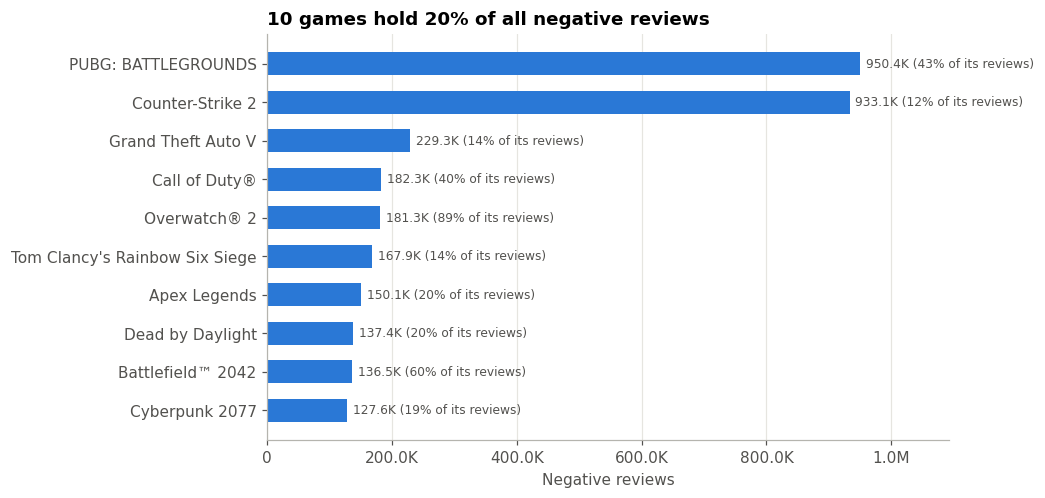

Negative reviews in all games: 16,356,741; in these 10 games: 3,195,903 (19.54%)
Their negative shares range from 12.1% to 88.7%
Games in both Figure 7 and Figure 8: 1 (Overwatch® 2)


In [30]:
top_by_count = top_games(game_stats, MIN_GAME_REVIEWS, TOP_GAMES_BY_COUNT,
                         rank_by='n_negative')
n_negative_total = game_stats['n_negative'].sum()
top_count_share = top_by_count['n_negative'].sum() / n_negative_total
plot_barh([shorten(name) for name in top_by_count['game']],
          top_by_count['n_negative'],
          title=f'{len(top_by_count)} games hold {top_count_share:.0%} '
                f'of all negative reviews',
          xlabel='Negative reviews',
          value_labels=[f'{format_count(n)} ({share:.0%} of its reviews)'
                        for n, share in zip(top_by_count['n_negative'],
                                            top_by_count['negative_share'])])
plt.show()

# Games in both rankings (Figures 7 and 8)
in_both = top_by_count[top_by_count['appid'].isin(top_by_share['appid'])]
print(f'Negative reviews in all games: {n_negative_total:,}; in these '
      f'{len(top_by_count)} games: {top_by_count["n_negative"].sum():,} '
      f'({top_count_share:.2%})')
print(f'Their negative shares range from '
      f'{top_by_count["negative_share"].min():.1%} to '
      f'{top_by_count["negative_share"].max():.1%}')
print(f'Games in both Figure 7 and Figure 8: {len(in_both)}'
      + (f' ({", ".join(in_both["game"])})' if len(in_both) else ''))

**Figure 8.** The 10 games with the most negative recommendations, labeled with the share of each game's reviews that are negative.

Figure 8 ranks games by volume instead of share. These 10 games account for 19.54% of all 16,356,741 negative recommendations, and PUBG: BATTLEGROUNDS (950.4 thousand) and Counter-Strike 2 (933.1 thousand) alone hold about 11.5%. Yet their own shares range from 12.1% (Counter-Strike 2) to 88.7% (Overwatch 2). Six of the ten are within six points of the overall share of 14.41%: Counter-Strike 2, Grand Theft Auto V, and Tom Clancy's Rainbow Six Siege are 12–14% negative, and Apex Legends, Dead by Daylight, and Cyberpunk 2077 are 19–20% negative. Only four are far above it: PUBG: BATTLEGROUNDS (43%), Call of Duty® (40%), Battlefield™ 2042 (60%), and Overwatch 2 (89%). Overwatch 2 is the only game that appears in both rankings. Most of these games are large online multiplayer games, so their volume of negative reviews reflects how many people play and review them more than how dissatisfied each reviewer is.

The two views answer different questions. Volume shows where most dissatisfied players are, which matters to community managers and to Steam, who must handle that volume. Share shows which games disappoint their own players most, which matters to developers judging the quality of a game and to players reading its score.

### 7.5 Robustness of the Ranking

The ranking of Section 7.3 rests on two choices: the 1,000-review threshold, and ranking games by their share. Table 15 repeats the ranking with thresholds of 500 and 5,000 reviews, and with games ranked by the lower bound of their 95% Wilson interval. The lower bound is a conservative rule: it places a game high only if its share is high *and* its number of reviews makes that share certain. For each variant, Table 15 counts how many of the 15 baseline games remain in the list.

In [31]:
# Table 15: repeat the ranking for every threshold and ranking rule, and
# count how many of the 15 baseline games each variant keeps
baseline_ids = set(top_by_share['appid'])
RANKINGS = {'share (Eq. 1)': 'negative_share',
            'lower bound of the 95% interval': 'ci_lower'}
sensitivity_rows = []
for threshold in GAME_THRESHOLDS:
    for ranking, column in RANKINGS.items():
        top = top_games(game_stats, threshold, TOP_GAMES_BY_SHARE, column)
        sensitivity_rows.append({
            'minimum reviews': threshold,
            'ranked by': ranking,
            'eligible games': int((game_stats['n_reviews']
                                   >= threshold).sum()),
            'shared with baseline': len(baseline_ids & set(top['appid'])),
            'first-ranked game': top['game'].iloc[0] if len(top) else '–',
        })
display(pd.DataFrame(sensitivity_rows)
        .set_index(['minimum reviews', 'ranked by'])
        .style.format({'eligible games': '{:,.0f}'}))

**Table 15.** The top-15 ranking under alternative thresholds and ranking rules: the number of eligible games, how many of the 15 games are also in the baseline list (1,000 reviews, ranked by share), and the first-ranked game.

Table 15 shows that the answer to RQ1 depends little on the threshold or the ranking rule. 三国杀 is the first-ranked game in all six variants. At 5,000 reviews, only 5 of the 15 baseline games remain, but these are exactly the five baseline games with at least 5,000 reviews (三国杀, Overwatch 2, NBA 2K24, StarForge, and Europa Universalis IV: Leviathan). No baseline game that stays eligible drops out; the ten other places go to games with 5,000 or more reviews that ranked below the baseline 15. At 500 reviews, 8 of the 15 remain: 3,393 more games become eligible, and some of those with 500 to 999 reviews have even higher shares. Ranking by the lower bound of the 95% interval keeps 13 of the 15 games at 1,000 reviews and 10 at 500 reviews, because the lower bound moves down games whose shares rest on fewer reviews. The games that change places are therefore those near the threshold, whose intervals in Table 14 are widest. The top of the RQ1 ranking is thus robust: the leading game does not change under any assumption tested, and well-measured games keep their place in the list, while the lower ranks depend on the threshold.

<a id="rq2"></a>
## 8. Negative Recommendations by Playtime, Year, and Language (RQ2)

This section answers RQ2 by comparing the negative share across three ways of grouping reviews: playtime at review (Section 8.1), review year (Section 8.2), and review language (Section 8.3). Each figure shows the pooled share (Equation 1) of every group against the overall share, and Section 8.4 checks each pattern against game-averaged shares. All comparisons are descriptive: a group with a higher share is not shown to *cause* negative reviews.

All views come from one aggregate: the number of reviews and of negative reviews for every combination of game, playtime band, review year, and language. It is computed in one pass over the analysis table, is far smaller than it, and is reused by every query in this section, so it is persisted (lecture: *Persistence*).

In [32]:
group_counts = (reviews
                .groupBy('appid', 'playtime_band',
                         F.year('created_at').alias('review_year'),
                         'language')
                .agg(F.count('*').alias('n_reviews'),
                     F.sum('is_negative').alias('n_negative'))
                .persist())
with timed('Aggregate reviews by game, band, year, and language'):
    n_combinations = group_counts.count()
print(f'Combinations of game, playtime band, year, and language: '
      f'{n_combinations:,}')


def negative_share_by(counts, column):
    """Pooled negative share (Equation 1) for each value of a column.

    Parameters
    ----------
    counts : pyspark.sql.DataFrame
        Aggregated reviews with ``n_reviews`` and ``n_negative``, such as
        ``group_counts``.
    column : str
        Column that defines the groups.

    Returns
    -------
    pandas.DataFrame
        Reviews, negative reviews, and negative share for each group.
    """
    return (counts.groupBy(column)
            .agg(F.sum('n_reviews').alias('n_reviews'),
                 F.sum('n_negative').alias('n_negative'))
            .withColumn('negative_share',
                        F.col('n_negative') / F.col('n_reviews'))
            .toPandas())

Aggregate reviews by game, band, year, and language: 0.8 min
Combinations of game, playtime band, year, and language: 3,761,547


### 8.1 Playtime at Review

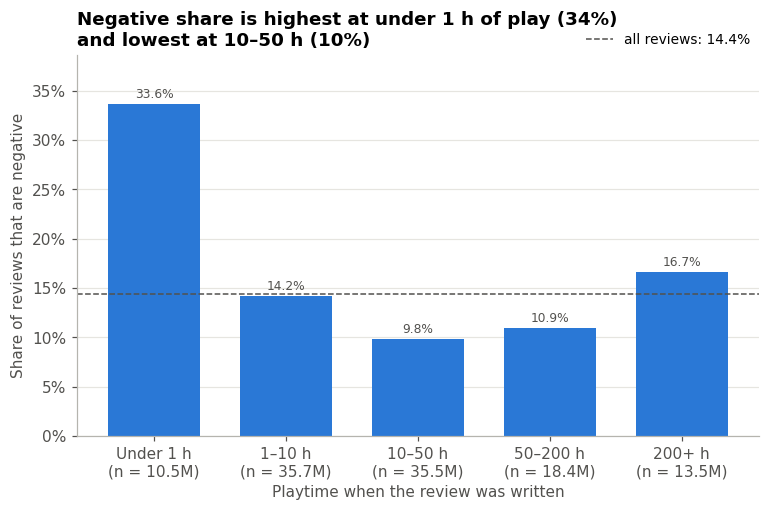

Under 1 h: 10,494,845 reviews (9.2%), negative share 33.63% = 2.33 times the overall
1–10 h: 35,666,184 reviews (31.4%), negative share 14.22% = 0.99 times the overall
10–50 h: 35,452,921 reviews (31.2%), negative share 9.85% = 0.68 times the overall
50–200 h: 18,395,397 reviews (16.2%), negative share 10.93% = 0.76 times the overall
200+ h: 13,521,074 reviews (11.9%), negative share 16.67% = 1.16 times the overall


In [33]:
def lower_first(text):
    """Lowercase the first letter of a label, e.g. 'Under 1 h'.

    Parameters
    ----------
    text : str
        Label to change.

    Returns
    -------
    str
        The label with a lowercase first letter.
    """
    return text[:1].lower() + text[1:]


by_band = (negative_share_by(group_counts, 'playtime_band')
           .set_index('playtime_band')
           .reindex(BAND_ORDER)
           .dropna(subset=['n_reviews'])
           .reset_index())
known_bands = by_band[by_band['playtime_band'] != UNKNOWN_BAND]
highest_band = known_bands.loc[known_bands['negative_share'].idxmax()]
lowest_band = known_bands.loc[known_bands['negative_share'].idxmin()]
plot_bars([f'{band}\n(n = {format_count(n)})'
           for band, n in zip(by_band['playtime_band'],
                              by_band['n_reviews'])],
          by_band['negative_share'],
          title=f'Negative share is highest at '
                f'{lower_first(highest_band["playtime_band"])} of play '
                f'({highest_band["negative_share"]:.0%})\nand lowest at '
                f'{lower_first(lowest_band["playtime_band"])} '
                f'({lowest_band["negative_share"]:.0%})',
          xlabel='Playtime when the review was written',
          ylabel='Share of reviews that are negative',
          colors=['#b5b4ae' if band == UNKNOWN_BAND else PRIMARY
                  for band in by_band['playtime_band']],
          value_labels=[f'{share:.1%}' for share in by_band['negative_share']],
          reference=overall_share,
          reference_label=f'all reviews: {overall_share:.1%}',
          percent=True)
plt.show()

for band, n, share in zip(by_band['playtime_band'], by_band['n_reviews'],
                          by_band['negative_share']):
    print(f'{band}: {n:,.0f} reviews ({n / n_clean:.1%}), negative share '
          f'{share:.2%} = {share / overall_share:.2f} times the overall')

**Figure 9.** Share of negative recommendations in each playtime-at-review band, with the number of reviews $n$ in each band. No review has unknown playtime (Section 5.8), so no *Unknown* band appears. The dashed line is the share across all retained reviews.

Figure 9 shows that reviews written after less than an hour of play are the most negative, at 33.63%, 2.33 times the overall share, although they make up only 9.2% of retained reviews. The share then falls to 14.22% at 1–10 hours and reaches its lowest value, 9.85%, at 10–50 hours, before rising again to 10.93% at 50–200 hours and 16.67% at 200 hours or more. The pattern is therefore U-shaped rather than steadily falling. The least satisfied reviewers are those who stopped very early, and the only other group above the overall share is the most experienced players.

Steam's refund policy offers one possible context for the early peak: a game played for less than two hours within 14 days of purchase can be refunded (Valve Corporation, n.d.-b), so some very early reviews may come from players who have already decided the game is not for them. The pattern is also consistent with Lin et al. (2019), who found that negative reviews tend to be posted after fewer hours of play than reviews in general. Part of the pattern is also built into the measure: players who dislike a game tend to stop playing it, so their reviews can only carry short playtimes, while long playtimes are mostly reached by players who enjoy the game. The rise at 200 hours or more shows that long play does not guarantee approval. Long-time players may be judging changes to a game they know well, but the data cannot show their reasons. Figure 9 therefore describes who reviews at each point of play; it does not show that more or less play changes how players feel. Section 8.4 checks whether the pattern holds within games.

### 8.2 Review Year

Retained reviews without a creation year (left out): 0
Last retained review: 2023-11-04 00:16:25 UTC


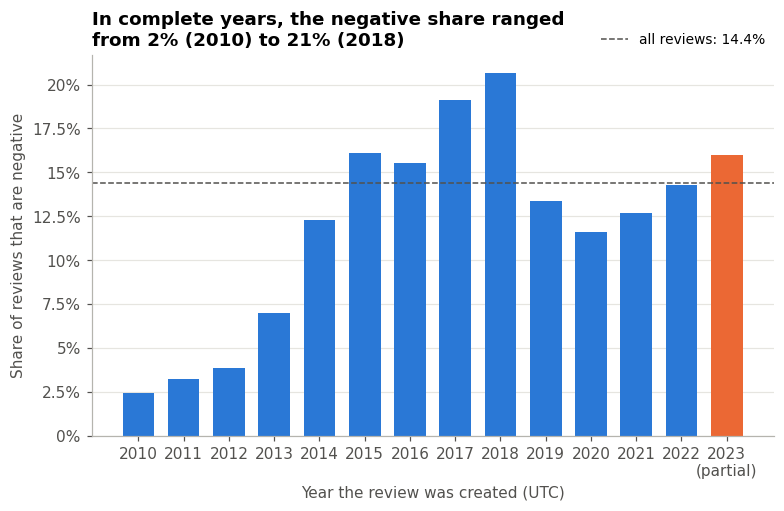

In [34]:
by_year = negative_share_by(group_counts, 'review_year')
undated = by_year['review_year'].isna()
print(f'Retained reviews without a creation year (left out): '
      f'{by_year.loc[undated, "n_reviews"].sum():,.0f}')
by_year = (by_year[~undated].astype({'review_year': int})
           .sort_values('review_year'))

last_clean_review = reviews.agg(F.max('created_at')).first()[0]
partial_year = (None if last_clean_review is None
                or (last_clean_review.month, last_clean_review.day)
                == (12, 31)
                else last_clean_review.year)
print(f'Last retained review: {last_clean_review} UTC')

# The title compares complete years with enough reviews to be stable
MIN_YEAR_REVIEWS = 10_000
complete_years = by_year[(by_year['review_year'] != partial_year)
                         & (by_year['n_reviews'] >= MIN_YEAR_REVIEWS)]
if complete_years.empty:  # e.g. a small development sample
    complete_years = by_year
high_year = complete_years.loc[complete_years['negative_share'].idxmax()]
low_year = complete_years.loc[complete_years['negative_share'].idxmin()]

plot_bars([f'{year}\n(partial)' if year == partial_year else str(year)
           for year in by_year['review_year']],
          by_year['negative_share'],
          title=f'In complete years, the negative share ranged\nfrom '
                f'{low_year["negative_share"]:.0%} '
                f'({int(low_year["review_year"])}) to '
                f'{high_year["negative_share"]:.0%} '
                f'({int(high_year["review_year"])})',
          xlabel='Year the review was created (UTC)',
          ylabel='Share of reviews that are negative',
          colors=[ACCENT if year == partial_year else PRIMARY
                  for year in by_year['review_year']],
          reference=overall_share,
          reference_label=f'all reviews: {overall_share:.1%}',
          percent=True)
plt.show()

**Figure 10.** Share of negative recommendations among reviews created in each year (UTC). The final year is partial: the last review was created on 4 November 2023. Every year has at least 10,000 reviews, so the title compares all years except the partial final one, although 2010 is also incomplete: it covers only the reviews from 16 October onward (Section 5.5). The dashed line is the share across all retained reviews; Figure 3 shows how many reviews each year holds, and Table 16 gives the exact counts and shares.

Figure 10 shows that the share of negative recommendations has changed considerably over time. It rose from 2.42% in 2010 and 3.23% in 2011 to 12.30% in 2014, reached its highest value, 20.67%, in 2018, fell to 11.62% in 2020, and has risen in each year since, to 14.28% in 2022 and 15.99% in the partial year 2023 (Table 16). The earliest years are unusual in two ways: their shares are far below the overall share, and they rest on few reviews (27,400 in 2010 and 179,374 in 2011, against more than 17 million in each year from 2020), so they are less stable and describe a much smaller catalog. The low point of 2020 coincides with the near doubling of the number of reviews that year (Figure 3); the data does not show whether the additional reviews came from more satisfied players or from different games. In 2023, Overwatch 2 alone contributes 181,292 negative reviews (Section 7.3), which raise that year's share by about 0.9 percentage points; without it, 2023 would still be about 15.1% negative, above 2022. Because 2023 ends on 4 November, its share covers reviews only up to that date. A change in the share over time mixes two effects: a change in how players feel, and a change in which games were reviewed in each year. Section 8.4 checks the second effect by averaging over games.

### 8.3 Review Language

The 10 most common languages hold 93.60% of retained reviews


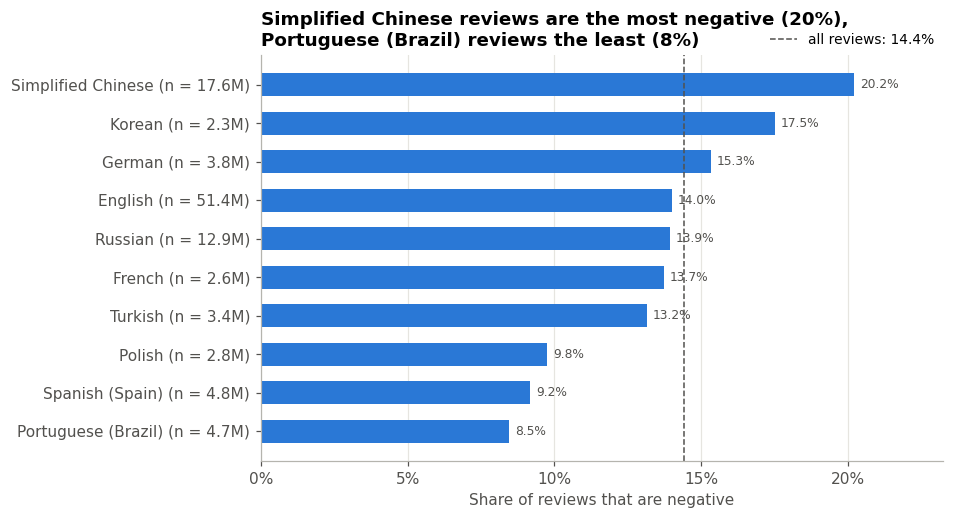

Gap between the most and least negative language: 11.7 percentage points


In [35]:
# Display names of Steam's language codes
LANGUAGE_NAMES = {
    'english': 'English', 'schinese': 'Simplified Chinese',
    'tchinese': 'Traditional Chinese', 'russian': 'Russian',
    'spanish': 'Spanish (Spain)', 'latam': 'Spanish (Latin America)',
    'brazilian': 'Portuguese (Brazil)', 'portuguese': 'Portuguese',
    'german': 'German', 'french': 'French', 'polish': 'Polish',
    'turkish': 'Turkish', 'koreana': 'Korean', 'japanese': 'Japanese',
    'italian': 'Italian', 'czech': 'Czech', 'thai': 'Thai',
    'ukrainian': 'Ukrainian', 'hungarian': 'Hungarian', 'dutch': 'Dutch',
    'swedish': 'Swedish', 'finnish': 'Finnish', 'danish': 'Danish',
    'norwegian': 'Norwegian', 'romanian': 'Romanian',
    'vietnamese': 'Vietnamese', 'greek': 'Greek', 'bulgarian': 'Bulgarian',
    'arabic': 'Arabic', 'indonesian': 'Indonesian', 'unknown': 'Unknown',
}

by_language = negative_share_by(group_counts, 'language')
top_language_shares = (by_language.nlargest(TOP_LANGUAGES, 'n_reviews')
                       .sort_values('negative_share', ascending=False))
covered = top_language_shares['n_reviews'].sum() / n_clean
print(f'The {TOP_LANGUAGES} most common languages hold {covered:.2%} of '
      f'retained reviews')

language_labels = [LANGUAGE_NAMES.get(code, code)
                   for code in top_language_shares['language']]
most_negative = top_language_shares.iloc[0]
least_negative = top_language_shares.iloc[-1]
plot_barh([f'{name} (n = {format_count(n)})'
           for name, n in zip(language_labels,
                              top_language_shares['n_reviews'])],
          top_language_shares['negative_share'],
          title=f'{language_labels[0]} reviews are the most negative '
                f'({most_negative["negative_share"]:.0%}),\n'
                f'{language_labels[-1]} reviews the least '
                f'({least_negative["negative_share"]:.0%})',
          xlabel='Share of reviews that are negative',
          value_labels=[f'{share:.1%}'
                        for share in top_language_shares['negative_share']],
          reference=overall_share,
          reference_label=f'all reviews: {overall_share:.1%}',
          percent=True)
plt.show()
gap = most_negative['negative_share'] - least_negative['negative_share']
print(f'Gap between the most and least negative language: '
      f'{gap * 100:.1f} percentage points')

**Figure 11.** Share of negative recommendations in the 10 most common review languages, sorted from most to least negative, with the number of reviews $n$ in each language. Steam's language codes are shown by name (e.g., `schinese` as Simplified Chinese, `koreana` as Korean). The dashed line is the share across all retained reviews.

The 10 most common languages hold 93.60% of retained reviews. Among them, Simplified Chinese reviews are the most negative at 20.20% and Portuguese (Brazil) reviews the least at 8.45%, a gap of 11.7 percentage points (Figure 11). Three languages are above the overall share: Simplified Chinese, Korean (17.50%), and German (15.33%). English, the largest language with 51.4 million reviews, is slightly below the overall share at 13.99%, close to Russian (13.93%) and French (13.71%). Polish (9.75%), Spanish (Spain) (9.16%), and Portuguese (Brazil) form the least negative group: in each, more than nine reviews in ten recommend the game. Language communities review different games, however, so part of these gaps may come from which games each community reviews rather than from the community itself; the Overwatch 2 reviews written in Simplified Chinese (Section 7.3) are one example. Section 8.4 separates the two.

### 8.4 Pooled versus Game-Averaged Shares

A pooled share (Equation 1 over all reviews in a group) gives every review the same weight, so it is dominated by the most reviewed games; Figure 4 showed how concentrated the reviews are. As an alternative assumption, the game-averaged share first computes each game's share within the group and then averages these shares, so that every game with at least 100 reviews in the group counts once. If the two shares agree, a pattern holds across games; if they disagree, it is driven by a few large games or by which games each group reviews. Table 16 compares them for every group of Figures 9–11, and the cell then prints, for each view, the rank correlation between the two shares (1 means that the groups keep the same order) and the group where they differ most.

In [36]:
def game_averaged_share(counts, column,
                        min_reviews=MIN_GAME_REVIEWS_PER_GROUP):
    """Average the per-game negative share within each group.

    Each game with at least ``min_reviews`` reviews in a group counts
    once, so a few heavily reviewed games cannot dominate the result.

    Parameters
    ----------
    counts : pyspark.sql.DataFrame
        Aggregated reviews with ``appid``, ``n_reviews``, and
        ``n_negative``, such as ``group_counts``.
    column : str
        Column that defines the groups.
    min_reviews : int
        Minimum reviews of a game within a group for it to count.

    Returns
    -------
    pandas.DataFrame
        Number of games and game-averaged share for each group.
    """
    return (counts.groupBy(column, 'appid')
            .agg(F.sum('n_reviews').alias('n'),
                 F.sum('n_negative').alias('negatives'))
            .filter(F.col('n') >= min_reviews)
            .groupBy(column)
            .agg(F.count('*').alias('games'),
                 F.avg(F.col('negatives') / F.col('n'))
                 .alias('game_averaged_share'))
            .toPandas())


top_language_list = list(top_language_shares['language'])
VIEWS = [
    ('Playtime band', group_counts, 'playtime_band', by_band),
    ('Review year', group_counts, 'review_year', by_year),
    ('Language',
     group_counts.filter(F.col('language').isin(top_language_list)),
     'language', top_language_shares),
]
comparison = []
for view, counts, column, pooled in VIEWS:
    averaged = game_averaged_share(counts, column).dropna(subset=[column])
    # Same key type on both sides (e.g. integer years)
    averaged[column] = averaged[column].astype(pooled[column].dtype)
    merged = pooled.merge(averaged, on=column, how='left')
    merged = merged.rename(columns={column: 'group'}).assign(view=view)
    if column == 'language':  # names, as in Figure 11
        merged['group'] = [LANGUAGE_NAMES.get(code, code)
                           for code in merged['group']]
    comparison.append(merged)
group_counts.unpersist()  # the Spark queries of Section 8 are done
comparison = (pd.concat(comparison)
              .astype({'group': str})
              .set_index(['view', 'group'])
              [['n_reviews', 'negative_share', 'games',
                'game_averaged_share']])
comparison['difference'] = (comparison['game_averaged_share']
                            - comparison['negative_share'])
display(comparison.style.format({
    'n_reviews': '{:,.0f}', 'negative_share': '{:.2%}', 'games': '{:,.0f}',
    'game_averaged_share': '{:.2%}', 'difference': '{:+.2%}'}, na_rep='–'))

# Do the groups keep the same order? Spearman correlation = correlation
# of the ranks
for view, rows in comparison.groupby(level='view', sort=False):
    rows = rows.dropna(subset=['game_averaged_share'])
    if len(rows) < 2:
        print(f'{view}: too few groups with games of '
              f'{MIN_GAME_REVIEWS_PER_GROUP}+ reviews')
        continue
    correlation = (rows['negative_share'].rank()
                   .corr(rows['game_averaged_share'].rank()))
    largest = rows['difference'].abs().idxmax()
    print(f'{view}: rank correlation {correlation:.2f}; largest difference '
          f'in {largest[1]} '
          f'({rows.loc[largest, "difference"] * 100:+.1f} percentage points)')

Playtime band: rank correlation 0.80; largest difference in 1–10 h (+4.0 percentage points)
Review year: rank correlation 0.93; largest difference in 2014 (+8.1 percentage points)
Language: rank correlation 0.88; largest difference in English (+7.4 percentage points)


**Table 16.** Pooled and game-averaged negative shares for every group of Figures 9–11. The game-averaged share counts each game with at least 100 reviews in the group once; *games* is the number of such games and *difference* is the game-averaged minus the pooled share, in percentage points.

Table 16 shows that the game-averaged shares largely keep the order of the pooled shares, with rank correlations of 0.80 for the playtime bands, 0.93 for the years, and 0.88 for the languages (printed above). The game-averaged share is higher than the pooled share in 26 of the 29 groups. The pooled share is dominated by the most reviewed games, and these tend to be less negative than the typical game.

- **Playtime.** The under-1-hour band remains by far the most negative after averaging over games (34.29%, against 33.63% pooled), so the early peak of Figure 9 holds within games and not only in the most reviewed ones. The rise at 200 hours or more, however, shrinks from 16.67% to 13.60% (−3.07 points), so it comes largely from a few heavily reviewed games with many long-time players. After averaging, the share falls from under 1 hour to 50–200 hours (11.07%) and rises only slightly afterwards.
- **Years.** The main features of Figure 10 survive: low shares up to 2013, the highest shares of the complete years in the second half of the 2010s (2015–2018 pooled, 2014–2018 game-averaged), and lower shares from 2019 to 2022. The largest difference is in 2014 (+8.10 points): the typical game reviewed in 2014 was 20.41% negative, although the pooled share was only 12.30%, so in the mid-2010s the most reviewed games were reviewed far more favorably than the rest. The peak of 2018 is almost the same in both views (20.67% and 20.96%), and the dip of 2020 is smaller after averaging (16.30%).
- **Languages.** Simplified Chinese is the language whose two shares agree most closely (20.20% pooled and 20.10% game-averaged, −0.10 points). Its high share is therefore not driven by a few large games such as Overwatch 2; it holds across 6,640 games. English shows the largest difference (+7.42 points), and its game-averaged share of 21.41% is the highest of the ten languages. English reviews cover far more games than any other language (16,106 games with at least 100 English reviews), including many small games with high shares, while its pooled share is held down by the large, mostly well-rated games that receive millions of English reviews. Polish, Spanish (Spain), and Portuguese (Brazil) remain the three least negative languages in both views.

Where the two shares agree, the pattern describes reviewers across the catalog; where they disagree, Section 10 reports the pattern with that caveat.

<a id="rq3"></a>
## 9. Words that Characterize Negative English Reviews (RQ3)

### 9.1 English Reviews and Tokenization

RQ3 uses English reviews only, because a word list is specific to one language and English is the largest language in the dataset (Figure 5). The words were extracted during staging (Section 4.5) with two Spark ML transformers (Apache Software Foundation, n.d.-b), which go beyond the lecture's approach to text (`split` and `explode` in *Working with Text files*):

1. **`RegexTokenizer`** lowercases each review and splits it at every run of characters that are not the letters a–z (pattern `[^a-z]+`). Only words made of letters remain: numbers, punctuation, emoji, and accented letters act as separators, and tokens of one letter are dropped. A contraction such as *didn't* becomes *didn* and *t*, and *t* is dropped.
2. **`StopWordsRemover`** removes Spark ML's default English stop-word list: function words such as *the* and *is*, and also negations such as *not* and *no*. That list spells contractions with an apostrophe (*didn't*), which the tokenizer has already split into a stem (*didn*), so the stems are not removed during staging. The cell below therefore also removes the stems that the tokenizer produces from the stop-word list itself (for example *didn*, *isn*, and *ll*), and prints them. This also removes *won* (from *won't*) and *let* (from *let's*), because after tokenization they cannot be told apart from the words *won* and *let*.
3. **`array_distinct`** reduces each review to its *set* of distinct words, because Equation 3 counts the reviews that contain a word, not how often the word occurs. A review that repeats a word counts once.

Two filtering steps define the base of RQ3, and the cell reports the number and proportion of reviews after each: keeping the English reviews, and keeping those with at least one content word left (reviews made only of stop words, numbers, emoji, or non-Latin text drop out).

In [37]:
DEFAULT_STOP_WORDS = StopWordsRemover.loadDefaultStopWords('english')
# Stems that the tokenizer makes from the list's own contractions, e.g.
# "didn't" -> "didn"; the stop-word list alone does not contain them
STOP_WORD_STEMS = sorted(
    {token for word in DEFAULT_STOP_WORDS
     for token in re.split('[^a-z]+', word.lower()) if len(token) >= 2}
    - set(DEFAULT_STOP_WORDS))
if STOP_WORD_STEMS:
    remaining_words = F.array_except(
        'words', F.array(*[F.lit(stem) for stem in STOP_WORD_STEMS]))
else:
    remaining_words = F.col('words')

# RQ3 base: English reviews, each with its set of remaining content words
# (null if none are left)
english_reviews = (reviews
                   .filter(F.col('language') == 'english')
                   .select('is_negative',
                           F.when(F.size(remaining_words) > 0,
                                  remaining_words).alias('terms')))

english_counts = (english_reviews
                  .agg(F.count('*').alias('english'),
                       F.sum(F.when(F.col('terms').isNotNull(),
                                    F.col('is_negative'))).alias('negative'),
                       F.count('terms').alias('with_words'))
                  .first())
n_english = english_counts.english
n_negative_docs = int(english_counts.negative or 0)            # N-
n_positive_docs = english_counts.with_words - n_negative_docs  # N+
assert n_negative_docs > 0 and n_positive_docs > 0
base_share = n_negative_docs / english_counts.with_words
print(f'Stop words removed: {len(DEFAULT_STOP_WORDS)} from Spark ML\'s '
      f'default English list, plus {len(STOP_WORD_STEMS)} contraction '
      f'stems: {", ".join(STOP_WORD_STEMS)}')
print(f'English reviews: {n_english:,} ({n_english / n_clean:.2%} of '
      f'retained reviews)')
print(f'With at least one content word: {english_counts.with_words:,} '
      f'({english_counts.with_words / n_english:.2%} of English reviews, '
      f'{english_counts.with_words / n_clean:.2%} of retained reviews)')
print(f'Negative, N-: {n_negative_docs:,}; positive, N+: '
      f'{n_positive_docs:,}; negative share of the RQ3 base: '
      f'{base_share:.2%}')

Stop words removed: 181 from Spark ML's default English list, plus 19 contraction stems: aren, couldn, didn, doesn, hadn, hasn, haven, isn, let, ll, mustn, re, shan, shouldn, ve, wasn, weren, won, wouldn
English reviews: 51,352,402 (45.23% of retained reviews)
With at least one content word: 49,941,105 (97.25% of English reviews, 43.99% of retained reviews)
Negative, N-: 7,037,243; positive, N+: 42,903,862; negative share of the RQ3 base: 14.09%


45.23% of retained reviews are in English, and 97.25% of those keep at least one content word after the 181 stop words of Spark ML's list and the 19 contraction stems printed above are removed. The base of RQ3 therefore holds 49,941,105 reviews, 43.99% of all retained reviews: $N^{-}$ = 7,037,243 negative and $N^{+}$ = 42,903,862 positive. Their negative share, 14.09%, is close to the overall share of 14.41%, so the English base is representative of all reviews in this respect.

### 9.2 Words Most Typical of Negative Reviews

The number of reviews containing each word is counted with the DataFrame API (`explode` and `groupBy`, as in the lecture's token count), then Equation 3 is computed with the SQL API. Only words found in at least the smallest threshold of Section 9.3 move to pandas.

Count reviews containing each word: 13.6 min
Words in at least 2,000 reviews: 17,250


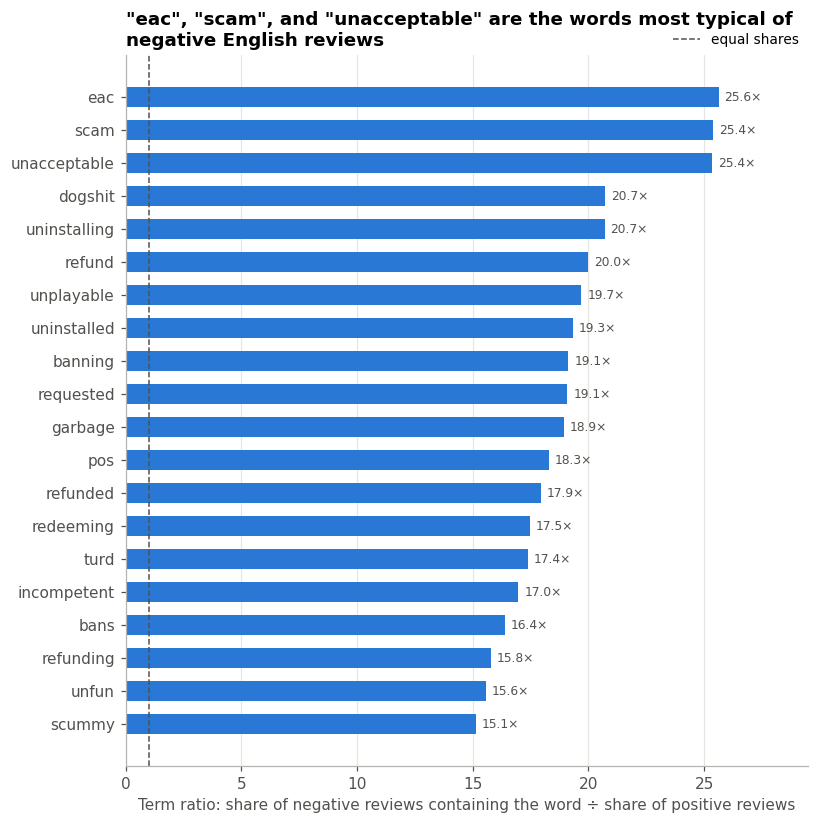

In [38]:
term_docs = (english_reviews
             .filter(F.col('terms').isNotNull())
             .select('is_negative', F.explode('terms').alias('term'))
             .groupBy('term')
             .agg(F.count('*').alias('n_reviews'),
                  F.sum('is_negative').alias('n_negative'))
             .filter(F.col('n_reviews') >= min(TERM_THRESHOLDS)))
term_docs.createOrReplaceTempView('term_docs')

TERM_RATIO_SQL = f"""
SELECT
    term,
    n_reviews,
    n_negative,
    n_reviews - n_negative AS n_positive,
    n_negative / n_reviews AS negative_share,
    n_negative / {n_negative_docs} AS negative_doc_share,
    (n_reviews - n_negative) / {n_positive_docs} AS positive_doc_share,
    -- Equation 3; null instead of an error if a word is never positive
    try_divide(n_negative / {n_negative_docs},
               (n_reviews - n_negative) / {n_positive_docs}) AS term_ratio
FROM term_docs
"""
with timed('Count reviews containing each word'):
    terms = spark.sql(TERM_RATIO_SQL).toPandas()
print(f'Words in at least {min(TERM_THRESHOLDS):,} reviews: {len(terms):,}')

top_terms = (terms[terms['n_reviews'] >= MIN_TERM_REVIEWS]
             .sort_values('term_ratio', ascending=False)
             .head(TOP_TERMS))
leaders = [f'"{term}"' for term in top_terms['term'].head(3)]
leaders_text = (', '.join(leaders[:-1]) + ', and ' + leaders[-1]
                if len(leaders) > 2 else ' and '.join(leaders))
plot_barh(top_terms['term'], top_terms['term_ratio'],
          title=f'{leaders_text} are the words most typical of\n'
                f'negative English reviews',
          xlabel='Term ratio: share of negative reviews containing the word '
                 '÷ share of positive reviews',
          value_labels=[f'{ratio:.1f}×' for ratio in top_terms['term_ratio']],
          reference=1, reference_label='equal shares')
plt.show()

**Figure 12.** The 20 words with the highest term ratio (Equation 3) among words found in at least 10,000 English reviews. A ratio of 5× means a negative review is five times as likely as a positive review to contain the word; the dashed line marks equal shares.

In [39]:
# Table 17: the words of Figure 12 with their counts and shares
display(top_terms
        .assign(rank=range(1, len(top_terms) + 1))
        .set_index('rank')
        [['term', 'n_reviews', 'n_negative', 'n_positive',
          'negative_doc_share', 'positive_doc_share', 'negative_share',
          'term_ratio']]
        .style.format({'n_reviews': '{:,.0f}', 'n_negative': '{:,.0f}',
                       'n_positive': '{:,.0f}',
                       'negative_doc_share': '{:.2%}',
                       'positive_doc_share': '{:.2%}',
                       'negative_share': '{:.1%}',
                       'term_ratio': '{:.2f}'}))

,term,n_reviews,n_negative,n_positive,negative_doc_share,positive_doc_share,negative_share,term_ratio
rank,,,,,,,,
1,eac,"15,207","12,284","2,923",0.17%,0.01%,80.8%,25.62
2,scam,"37,708","30,404","7,304",0.43%,0.02%,80.6%,25.38
3,unacceptable,"26,586","21,432","5,154",0.30%,0.01%,80.6%,25.35
4,dogshit,"29,636","22,902","6,734",0.33%,0.02%,77.3%,20.73
5,uninstalling,"22,362","17,273","5,089",0.25%,0.01%,77.2%,20.69
6,refund,"239,780","183,712","56,068",2.61%,0.13%,76.6%,19.98
7,unplayable,"221,677","169,278","52,399",2.41%,0.12%,76.4%,19.70
8,uninstalled,"48,964","37,220","11,744",0.53%,0.03%,76.0%,19.32
9,banning,"14,046","10,652","3,394",0.15%,0.01%,75.8%,19.13


**Table 17.** The words of Figure 12 with the number of English reviews that contain them ($d^{-}_{w} + d^{+}_{w}$), split into negative ($d^{-}_{w}$) and positive ($d^{+}_{w}$) reviews; the share of all negative and of all positive reviews that contain them; the share of the reviews containing them that are negative (*negative_share*); and the term ratio $r_w$.

Figure 12 and Table 17 show that the 20 words most typical of negative reviews are 15 to 26 times more likely to appear in a negative review than in a positive one. They fall into four themes:

1. **Money, refunds, and fraud:** *scam* (25.4×), *refund* (20.0×), *refunded* (17.9×), *refunding* (15.8×), and *scummy* (15.1×). *Requested* (19.1×) probably belongs here as well, as in a requested refund.
2. **Games that cannot be played or kept:** *unplayable* (19.7×), *uninstalling* (20.7×), and *uninstalled* (19.3×).
3. **Anti-cheat and bans:** *eac* (25.6×), most likely Easy Anti-Cheat, a cheat-detection service used by many online games, with *banning* (19.1×) and *bans* (16.4×).
4. **Blunt condemnation of the game or its developers:** *unacceptable* (25.4×), *dogshit* (20.7×), *garbage* (18.9×), *pos* (18.3×, most likely an abbreviated insult), *turd* (17.4×), *incompetent* (17.0×), and *unfun* (15.6×).

The strongest word, *eac*, appears in 0.17% of negative reviews but only 0.01% of positive ones, and 80.8% of the reviews that contain it are negative, against 14.09% of the RQ3 base. The more common words of the list reach many more reviews, however. *Refund* appears in 239,780 reviews, in 2.61% of all negative reviews against 0.13% of positive ones, and *unplayable* and *garbage* each appear in about 220,000 reviews. One word only makes sense in context: *redeeming* (17.5×) most likely comes from phrases such as "no redeeming qualities", whose negation was removed as a stop word (Section 9.1).

Read together, the themes describe concrete dissatisfaction. Negative reviewers complain about losing money, about games they cannot run or are banned from, and about developers they consider incompetent, more than about matters of taste. The refund words are consistent with the high share of negative reviews written in the first hour of play (Figure 9), when a refund is still possible, but this link is an interpretation: the analysis does not cross word use with playtime.

### 9.3 Robustness and Contrast

Two checks test the word list. Table 18 repeats the ranking with minimums of 2,000 and 50,000 reviews instead of 10,000. A lower minimum admits rarer words, whose ratios can be larger but rest on less evidence; a higher minimum keeps only common words. Table 19 lists the words most typical of *positive* reviews at the baseline minimum, as a contrast: if the negative words name specific complaints rather than general emotion, the two lists should differ in kind, not only in tone.

In [40]:
# Table 18: repeat the word ranking for every minimum number of reviews,
# and count how many of the 20 baseline words each variant keeps
baseline_terms = set(top_terms['term'])
term_sensitivity = []
for threshold in TERM_THRESHOLDS:
    top = (terms[terms['n_reviews'] >= threshold]
           .sort_values('term_ratio', ascending=False)
           .head(TOP_TERMS))
    term_sensitivity.append({
        'minimum reviews': threshold,
        'eligible words': int((terms['n_reviews'] >= threshold).sum()),
        'shared with baseline': len(baseline_terms & set(top['term'])),
        'top five words': ', '.join(top['term'].head(5)),
    })
display(pd.DataFrame(term_sensitivity).set_index('minimum reviews')
        .style.format({'eligible words': '{:,.0f}'}))

,eligible words,shared with baseline,top five words
minimum reviews,,,
2000,"17,250",5,"openiv, tencent, abandonware, disgraceful, disgrace"
10000,"7,255",20,"eac, scam, unacceptable, dogshit, uninstalling"
50000,"2,563",4,"refund, unplayable, garbage, refunded, trash"


**Table 18.** The top-20 word list under alternative minimum numbers of reviews: eligible words, how many of the 20 are also in the baseline list (10,000 reviews), and the top five words.

In [41]:
# Table 19: the 10 words with the lowest term ratio, i.e. the words most
# typical of positive reviews
positive_terms = (terms[terms['n_reviews'] >= MIN_TERM_REVIEWS]
                  .sort_values('term_ratio')
                  .head(10))
display(positive_terms.set_index('term')
        [['n_reviews', 'negative_doc_share', 'positive_doc_share',
          'negative_share', 'term_ratio']]
        .style.format({'n_reviews': '{:,.0f}',
                       'negative_doc_share': '{:.2%}',
                       'positive_doc_share': '{:.2%}',
                       'negative_share': '{:.1%}',
                       'term_ratio': '{:.2f}'}))

,n_reviews,negative_doc_share,positive_doc_share,negative_share,term_ratio
term,,,,,
noice,"48,317",0.01%,0.11%,1.0%,0.06
goog,"11,441",0.00%,0.03%,1.0%,0.06
vroom,"16,445",0.00%,0.04%,1.1%,0.07
guud,"11,788",0.00%,0.03%,1.2%,0.08
pog,"65,379",0.01%,0.15%,1.2%,0.08
poggers,"29,173",0.01%,0.07%,1.3%,0.08
goated,"16,111",0.00%,0.04%,1.5%,0.09
funni,"10,744",0.00%,0.02%,1.5%,0.09
monke,"38,408",0.01%,0.09%,1.5%,0.10


**Table 19.** The 10 words with the lowest term ratio among words found in at least 10,000 English reviews: the words most typical of positive reviews, with the share of negative and positive reviews that contain them and the share of their reviews that are negative.

Table 18 shows that the exact list depends on the minimum, but its main themes do not. At 2,000 reviews, 17,250 words are eligible, rarer words reach higher ratios, and only 5 of the 20 baseline words remain. The new leaders name specific disputes and grievances. *Openiv* is the name of a modding tool for Grand Theft Auto V; its shutdown after a cease-and-desist letter from the game's publisher in June 2017 led players to flood the game with negative reviews (Bishop, 2017). *Tencent* is the name of a large Chinese technology and game company, and *abandonware* describes games that their developers stopped supporting. *Disgraceful* and *disgrace* join the theme of condemnation. At 50,000 reviews, only 2,563 words are eligible, and 4 baseline words remain: *refund*, *unplayable*, *garbage*, and *refunded*. These are exactly the four baseline words found in at least 50,000 reviews, so no baseline word that stays eligible drops out, and *trash* joins them in the top five. Words of condemnation appear at every minimum, and refund and playability words lead the list when only common words are allowed. The minimum mainly decides whether the list shows widespread complaints (high minimum) or single controversies (low minimum). The *openiv* example probably also links RQ3 to RQ1, since Grand Theft Auto V has the third-largest number of negative reviews of any game (Figure 8).

The words most typical of positive reviews (Table 19) are of a different kind. They are informal expressions of enthusiasm and internet slang, such as *noice*, *pog*, *poggers*, *goated*, and *monke*, playful spellings of *good* and *funny* (*goog*, *guud*, *funni*), the sound *vroom*, and *underrated*, with ratios as low as 0.06: only 1.0% to 1.6% of the reviews that contain them are negative. Negative reviews name concrete problems and judge the developers, while positive reviews express general approval in short, informal words without naming specific features. Dissatisfaction is therefore expressed more specifically than satisfaction, which matches the observation of Lin et al. (2019) that negative reviews contain more of the information that developers can act on.

<a id="results"></a>
## 10. Results and Discussion

This section first answers each research question from the results of Sections 7 to 9 (Section 10.1), then combines the three views into one picture of dissatisfaction (Section 10.2), and finally discusses what the findings mean within and beyond Steam (Section 10.3).

### 10.1 Answers to the Research Questions

**RQ1. Which games with at least 1,000 reviews have the highest shares of negative recommendations?** Among the 6,682 games with at least 1,000 retained reviews, the highest shares belong to 三国杀 (91.0% of 39,296 reviews), SuperPower 3 (89.5%), the War Thunder - Air Forces High-res Texture Pack (89.4%), Europa Universalis IV: Leviathan (88.7%), and Overwatch 2 (88.7% of 204,330 reviews). All 15 games of Figure 7 are 82.1–91.0% negative, 5.7 to 6.3 times the overall share of 14.41%, with 95% intervals no wider than 4.6 percentage points (Table 14). Four of them are add-ons to another game. The top of the list is robust: 三国杀 ranks first under every threshold and ranking rule tested, and every baseline game that remains eligible at 5,000 reviews stays in the list (Table 15). The lower ranks, however, change with the threshold: only 8 of the 15 games remain at 500 reviews. The games with the highest shares are not the ones with the most negative reviews. The ten games with the most negative reviews hold 19.5% of all 16.4 million negatives, yet six of them are only 12–20% negative, and Overwatch 2 is the only game in both rankings (Figure 8).

**RQ2. How does the negative-recommendation share differ by playtime at review, review year, and review language?**

- **Playtime.** The share is U-shaped: 33.6% after less than an hour of play, 2.3 times the overall share; lowest at 10–50 hours (9.8%); and higher again at 200 hours or more (16.7%) (Figure 9). The early peak holds within games (34.3% game-averaged), while most of the late rise comes from a few large games (13.6% game-averaged) (Table 16).
- **Year.** The share rose from 2–4% in 2010–2012 to a peak of 20.7% in 2018, fell to 11.6% in 2020, and has risen since, to 16.0% in the partial year 2023 (Figure 10). Averaged over games, the peak spans 2014–2018 at 20–22%, and later years lie at 16–18% (Table 16).
- **Language.** Among the ten most common languages, Simplified Chinese reviews are the most negative (20.2%) and Portuguese (Brazil) reviews the least (8.5%), a gap of 11.7 percentage points (Figure 11). Simplified Chinese stays at 20.1% when every game counts once, and Polish, Spanish (Spain), and Portuguese (Brazil) stay the least negative. English moves from slightly below the overall share (14.0%) to the highest game-averaged share (21.4%), because English reviews cover many more small games (Table 16).

**RQ3. Which words appear far more often in negative English reviews than in positive ones?** Among the 7,255 words found in at least 10,000 English reviews, the words most typical of negative reviews are *eac* (25.6 times as likely in a negative as in a positive review), *scam* (25.4), *unacceptable* (25.4), *dogshit* (20.7), *uninstalling* (20.7), and *refund* (20.0) (Figure 12). The top 20 fall into four themes: money and refunds, unplayable games, anti-cheat and bans, and blunt condemnation of games and developers (Table 17). Words of condemnation are among the top five at every minimum tested, while refund and playability words lead when only common words are allowed (Table 18). Positive reviews, in contrast, are marked by informal praise such as *noice* and *pog* rather than by specific features (Table 19).

### 10.2 What the Patterns Show Together

**Dissatisfaction is concentrated, not spread evenly.** Only one review in seven is negative overall (14.41%), but the share reaches 82–91% for the most criticized games (Figure 7), one in three reviews in the first hour of play (Figure 9), and one in five Simplified Chinese reviews (Figure 11). Volume is concentrated as well: ten games hold a fifth of all negative reviews (Figure 8). An average across the catalog therefore hides most of the variation that matters to a developer or a platform.

**Early disappointment and money go together.** The two strongest patterns of RQ2 and RQ3 point in the same direction. Reviews written in the first hour are the most negative, and the effect holds within games (Table 16), while words about refunds and scams are among the most typical of negative reviews (Table 17). Steam allows refunds for games played for less than two hours (Valve Corporation, n.d.-b), so a plausible reading is that much early dissatisfaction comes from players who decide quickly that a game is not worth its price. This reading goes beyond the data, because the analysis did not cross word use with playtime; Section 12.3 proposes that test.

**Disputes leave visible traces in every view.** Several of the strongest signals come from conflicts between players and publishers rather than from gameplay alone. Overwatch 2, released on Steam in August 2023 amid protest by Chinese players (Obedkov, 2023), is among the most negative games by share and by volume (Figures 7 and 8) and adds about 0.9 percentage points to the share of 2023 (Section 8.2). The words *openiv* and *tencent*, which lead the word list at 2,000 reviews (Table 18), name a modding dispute around Grand Theft Auto V (Bishop, 2017) and a company. *Eac*, *banning*, and *bans* point to conflicts over anti-cheat systems. These are interpretations of named games and words, supported by news reports, not results of the data; but they suggest that a large part of dissatisfaction is a reaction to decisions about a game, such as its price model, its support, or its rules, and not only to the game as it was released.

**What is counted shapes the answer.** Comparing pooled and game-averaged shares changed three conclusions (Table 16). The rise in negativity after 200 hours largely disappears when every game counts once, English reviews move from below average to the most negative language, and 2014 moves from a below-average year to one of the most negative. The most reviewed games are, on the whole, rated better than the typical game, so pooled statistics understate the dissatisfaction that a typical game faces. Only the patterns that hold in both views (the first-hour peak, the mid-2010s peak, and the high share of Simplified Chinese reviews) describe reviewers across the catalog.

**Language communities differ, but the reasons are open.** Simplified Chinese reviews are among the most negative in both views (the most negative pooled, and second only to English when averaged over games), while Brazilian Portuguese, Spanish, and Polish reviews are the least negative in both views (Table 16). Such differences could reflect reviewing norms, regional prices, servers, or the quality of localization and support, and the data cannot separate these explanations.

### 10.3 Significance and Impact

Within Steam, the results tell each group where to look. Developers learn that the first hour of play is the most review-sensitive stage of a game, and that complaints about refunds, playability, and bans are the clearest signs of a negative review. Community managers learn which language communities are the most critical across games, so that responses and localized support can be planned accordingly. Steam and other platforms learn that a small number of games produce a large share of negative reviews, and that dispute-driven waves, such as that of Overwatch 2, can be detected from sudden changes in a game's share and vocabulary. Players and journalists learn that a game's share has to be read together with its number of reviews, and that a high volume of negative reviews does not mean a high share.

Beyond this study, the findings and the method transfer to other settings:

- **Any large review corpus.** The pipeline uses only Spark's built-in functions and needs only an item, a recommendation or rating, and text, plus whatever grouping fields are available (here playtime, year, and language). It can therefore be applied to app-store, e-commerce, or other game-platform reviews, and to a newer Steam snapshot, without new code.
- **A cheap monitoring dashboard.** The three measures of Section 3.2, a share with its Wilson interval, a game-averaged share, and a term ratio, need only counts. They can be updated daily for millions of reviews and form a monitoring tool for any platform that collects ratings with text.
- **Reading aggregate satisfaction scores.** The difference between pooled and game-averaged shares (Table 16) applies to any average across items of very unequal size, such as a store's average rating or a company's satisfaction score. Reporting both views shows whether a pattern describes the typical item or only the largest ones.
- **Handling large, unsplittable text files.** The design of Sections 4.4 and 4.5, which reads a multi-line CSV once, checks it for malformed values, and stages a compact columnar table, applies to any large text export that cannot be split and must be analyzed on limited hardware.

<a id="conclusion"></a>
## 11. Conclusion

This report asked what patterns characterize player dissatisfaction in Steam reviews, and answered it by analyzing all 113,530,421 retained reviews of a 42 GB dataset with Apache Spark, of which 14.41% do not recommend the game. Player dissatisfaction in Steam reviews is concentrated rather than evenly spread: it clusters in a small set of heavily criticized games, peaks among reviewers who write after less than an hour of play, varies with review year and language, and is expressed through concrete complaints about money and refunds, unplayable games, anti-cheat bans, and developers' conduct. For RQ1, the 15 most criticized games with at least 1,000 reviews are 82.1–91.0% negative, led by 三国杀 at 91.0%, which ranks first under every threshold and ranking rule tested, while the lower ranks of the list change with the threshold. For RQ2, reviews written after less than one hour of play are 33.6% negative, 2.3 times the overall share and consistently so within games; the share peaked at 20.7% in 2018; and it ranges from 8.5% for Portuguese (Brazil) to 20.2% for Simplified Chinese among the ten largest languages. For RQ3, words such as *eac*, *scam*, *unacceptable*, and *refund* are 20 to 26 times more likely to appear in negative than in positive English reviews.

<a id="recommendations"></a>
## 12. Recommendations

### 12.1 For Developers, Community Managers, and Platforms

- **Watch the first hour of play.** One review in three written after less than an hour of play is negative (33.6%, Figure 9), and this holds within games (34.3%, Table 16). Developers should treat the first hour, including installation, performance, onboarding, and whether the game matches its store page, as the most review-sensitive part of a game. They should also track the negative share of early-playtime reviews separately after each launch or major update, since these reviews arrive while refunds are still possible (Valve Corporation, n.d.-b).
- **Track the complaint themes of Figure 12 in your own reviews.** Words about refunds, unplayability, anti-cheat bans, and developer conduct mark negative reviews (Table 17). Counting words such as *refund*, *unplayable*, *scam*, *eac*, and *ban* in a game's own reviews, against the base rates of Table 17, can flag rising dissatisfaction and its cause before the score falls into the *Mostly Negative* range, where Steam features a game less (Valve Corporation, n.d.-c). Games that use third-party anti-cheat software should explain bans and compatibility issues clearly, since *eac* is the single word most typical of negative reviews.
- **Prioritize community responses by language.** Simplified Chinese reviews are the most negative of the ten main languages when pooled (20.2%, Figure 11) and remain among the most negative when averaged over games (20.1%, second only to English at 21.4%, Table 16), and Korean and German reviews are also above the overall share. Publishers with large audiences in these languages should check whether localization, servers, support, or regional pricing explain the gap, and staff their responses in these languages accordingly.
- **Read review scores with the volume behind them.** A game can hold one of the largest numbers of negative reviews while being only 12% negative (Counter-Strike 2, Figure 8), and the typical game is more negative than pooled statistics suggest (Table 16). Platforms and journalists should report a game's share together with its number of reviews and its interval (Figure 7), and report catalog-wide statistics both pooled and averaged over games.
- **Detect dispute-driven waves early.** Overwatch 2 in 2023 and the OpenIV dispute in 2017 show that a single decision can trigger a large, fast wave of negative reviews (Section 7.3 and Table 18). Watching for sudden rises in a game's negative share together with new, game-specific words, such as the name of a tool or a company, would let community teams and Steam respond while the wave is still forming.

### 12.2 Limitations

**Self-selected reviewers.** Every share describes players who chose to write a review, not all players (Section 2.3). If dissatisfied players are more likely to write reviews, the shares overstate dissatisfaction among all players; if satisfied players are, the shares understate it. Comparisons between games and groups remain fair only if the tendency to review is similar across them, which this data cannot check.

**Descriptive, not causal.** Playtime, year, and language go together with negativity but are not shown to cause it. The first-hour peak, for example, is partly built into the measure, because players who dislike a game stop playing early (Section 8.1), and the differences between languages may come from the games each community plays, its prices, or its reviewing norms (Section 10.2).

**Pooled shares favor large games.** Pooled shares weight the most reviewed games heavily. Section 8.4 addresses this with game-averaged shares, but these in turn give a game with 100 reviews in a group the same weight as a game with millions. Because the two views disagree for English reviews, the 200+ hour band, and 2014, these three findings depend on how games are weighted and are reported with that caveat.

**Bag of words.** Single words ignore negation and context: *redeeming* is most likely typical of negative reviews because of phrases such as "no redeeming qualities" (Section 9.2). The letter-only tokenizer drops numbers and accented letters and splits contractions, and abbreviations such as *pos* and *eac* need interpretation. Only English reviews, 45% of the data, are analyzed, so the complaint themes may not describe other communities, including the most negative one, Simplified Chinese.

**Snapshot and coverage.** The data ends on 4 November 2023, so 2023 is partial, and later edits or deletions are not reflected. Unless the dataset author changed the API's default, reviews that Steam flagged as off-topic review bombs are absent (Section 2.3). If so, dispute-driven negativity is underestimated, although the Overwatch 2 reviews show that much of it remains in the data.

**Cleaning choices.** Duplicated reviews are kept once, under the lowest `appid` among their copies (Section 6.3). Because the copies almost always differ only in game, this assigns 332,865 reviews to one of two or three related products by convention, slightly changing their counts in RQ1, and 29 appids lose all their reviews. The *Unknown* playtime band planned for missing values turned out to be empty, so that choice did not affect any result. However, 1,871,268 reviews record a playtime of exactly zero (Section 5.8) and are counted in the under-1-hour band. If a zero means untracked time rather than very short play, part of the first-hour peak of Figure 9 may come from reviewers who played longer; comparing the negative share of zero-playtime reviews with that of other early reviews would settle this.

**Artifacts in unused columns.** `votes_funny` and `comment_count` contain values close to 2³², and one review has almost ten million characters (Sections 5.2 and 5.9). These do not affect any result, but they show that the raw data contains errors that a study using these columns would have to clean first.

### 12.3 Future Work

**Phrases instead of single words.** Spark ML's `NGram` transformer can count two- and three-word phrases. This would keep negations, such as "not worth" and "no redeeming", and expressions such as "pay to win", and so address the main weakness of the bag-of-words approach (Section 12.2).

**Topic models.** Spark ML's `LDA` could group complaint words into themes automatically, rather than by reading the top 20 words, and could be run per game to show which theme dominates each game of Figure 7.

**A more stable word measure.** A weighted log-odds ratio with an informative Dirichlet prior (Monroe et al., 2008) shrinks the scores of rare words and gives each word a z-score. It would replace the fixed minimum number of reviews of Equation 3, to which the word list is sensitive (Table 18).

**Words by playtime.** Crossing the term ratio with the playtime bands of RQ2 would test directly whether refund words concentrate in the first hour of play, which Section 10.2 could only suggest.

**Other languages.** Language-specific tokenizers and stop-word lists, starting with Simplified Chinese and Russian, would show whether the complaint themes of English reviews also hold in the most negative communities.

**Time windows around events.** Daily or weekly shares around launches, updates, and disputes would detect waves of negative reviews, such as those of Overwatch 2 and Grand Theft Auto V, and separate them from the long-term trend of Figure 10.

**Game metadata.** Joining genre, price, release date, and business model from Steam's store data would explain part of the differences between games, languages, and years, for example whether add-ons and free-to-play games are more often reviewed negatively.

**Scale and freshness.** Running the pipeline on a newer snapshot would complete 2023 and extend the trend. Storing the raw data in a splittable format, such as Parquet or JSON Lines, would remove the single-core read of Section 4.4 and let the same pipeline run on a multi-node cluster.

<a id="references"></a>
## 13. References

Apache Software Foundation. (n.d.-a). *CSV files*. Apache Spark documentation. https://spark.apache.org/docs/latest/sql-data-sources-csv.html

Apache Software Foundation. (n.d.-b). *Extracting, transforming and selecting features*. Apache Spark documentation. https://spark.apache.org/docs/latest/ml-features.html

Apache Software Foundation. (n.d.-c). *Migration guide: SQL, Datasets and DataFrame*. Apache Spark documentation. https://spark.apache.org/docs/latest/sql-migration-guide.html

Armbrust, M., Xin, R. S., Lian, C., Huai, Y., Liu, D., Bradley, J. K., Meng, X., Kaftan, T., Franklin, M. J., Ghodsi, A., & Zaharia, M. (2015). Spark SQL: Relational data processing in Spark. In *Proceedings of the 2015 ACM SIGMOD International Conference on Management of Data* (pp. 1383–1394). ACM. https://doi.org/10.1145/2723372.2742797

Bishop, R. (2017, June 17). *Players are punishing 'Grand Theft Auto V' publisher for killing modding tool*. Vice. https://vice.com/en/article/players-are-punishing-grand-theft-auto-v-publisher-for-killing-modding-tool

Chevalier, J. A., & Mayzlin, D. (2006). The effect of word of mouth on sales: Online book reviews. *Journal of Marketing Research, 43*(3), 345–354. https://doi.org/10.1509/jmkr.43.3.345

KieranPO'C. (2023). *100 million+ Steam reviews* (Version 2) [Data set]. Kaggle. https://www.kaggle.com/datasets/kieranpoc/steam-reviews

Lin, D., Bezemer, C.-P., Zou, Y., & Hassan, A. E. (2019). An empirical study of game reviews on the Steam platform. *Empirical Software Engineering, 24*(1), 170–207. https://doi.org/10.1007/s10664-018-9627-4

Monroe, B. L., Colaresi, M. P., & Quinn, K. M. (2008). Fightin' words: Lexical feature selection and evaluation for identifying the content of political conflict. *Political Analysis, 16*(4), 372–403. https://doi.org/10.1093/pan/mpn018

Obedkov, E. (2023, August 14). *Chinese players bashing Overwatch 2 on Steam to express their frustration with Blizzard's exit from China*. Game World Observer. https://gameworldobserver.com/2023/08/14/overwatch-2-chinese-negative-reviews-lowest-rated-steam-game

Shafranovich, Y. (2005). *Common format and MIME type for comma-separated values (CSV) files* (RFC 4180). Internet Engineering Task Force. https://doi.org/10.17487/RFC4180

Valve Corporation. (n.d.-a). *IUserReviewsService*. Steamworks documentation. https://partner.steamgames.com/doc/webapi/IUserReviewsService

Valve Corporation. (n.d.-b). *Steam refunds*. https://store.steampowered.com/steam_refunds

Valve Corporation. (n.d.-c). *User reviews*. Steamworks documentation. https://partner.steamgames.com/doc/store/reviews

Valve Corporation. (n.d.-d). *User reviews – Get list*. Steamworks documentation. https://partner.steamgames.com/doc/store/getreviews

Valve Corporation. (2024). *Steam annual roundup: 2023 edition* [News post]. Steam. https://store.steampowered.com/news/group/4145017/view/4031353003322171823

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953

Zaharia, M., Xin, R. S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X., Rosen, J., Venkataraman, S., Franklin, M. J., Ghodsi, A., Gonzalez, J., Shenker, S., & Stoica, I. (2016). Apache Spark: A unified engine for big data processing. *Communications of the ACM, 59*(11), 56–65. https://doi.org/10.1145/2934664

<a id="appendix-a"></a>
## Appendix A. Reproducibility and Supplementary Files

Table 20 lists every file submitted with this report, and Table 21 records the runtime and environment of the final run.

**Table 20.** Files submitted with this report. No raw, staged, or cleaned data is included.

| File | Purpose |
|---|---|
| `Lab2_SteamReviews_Report.ipynb` | This report; runs from top to bottom and regenerates every result |
| `Lab2_SteamReviews_Report.html` | HTML export of the executed notebook |
| `make_pipeline_diagram.py` | Supplementary script that draws Figure 1 (Section 3.1) |
| `figures/pipeline_overview.png` | Figure 1, as generated by the script |
| `figures/du_sch_raw_data.png` | Figure 2: terminal screenshot of `du -sch` on the raw input |

To reproduce the results, run this notebook on Jojie, where the raw file is in `/mnt/data/public/steam-reviews/all_reviews/` (`RAW_DIR`, Section 4.2). Keep `DEV_ROW_LIMIT = None` and run the notebook from top to bottom with PySpark 4 and Java 17 or later. The staging pass (Section 4.5) reads the raw file once and is the slowest step, because it runs on one core; later runs reuse `scratch/` if it still exists. The final run reused a staged table written by an earlier full pass over the file, so Table 21 does not include the staging pass. Delete `scratch/` after the final run: it holds processed data, which is not submitted.

In [42]:
# Runtime of the expensive steps and the environment of this run
display(pd.Series(RUNTIMES, name='minutes').div(60).round(1).to_frame())
print(f'Python {sys.version.split()[0]}, Spark {spark.version}, '
      f'pandas {pd.__version__}')
for setting in ['spark.master', 'spark.driver.memory',
                'spark.sql.shuffle.partitions', 'spark.sql.session.timeZone']:
    print(f'{setting} = {spark.conf.get(setting, "default")}')
if DEV_ROW_LIMIT:
    print(f'WARNING: development run on the first {DEV_ROW_LIMIT:,} '
          f'reviews only. Set DEV_ROW_LIMIT = None for the final report.')

spark.stop()

,minutes
Count records without multiLine (parallel),11.9
Count staged rows,0.0
Profile all raw columns,7.4
Count rows after each filtering step,1.7
Write the cleaned analysis table,14.0
Aggregate reviews per game,1.2
"Aggregate reviews by game, band, year, and language",0.8
Count reviews containing each word,13.6


Python 3.12.13, Spark 4.1.1, pandas 2.3.3
spark.master = local[*]
spark.driver.memory = 16g
spark.sql.shuffle.partitions = 400
spark.sql.session.timeZone = UTC


**Table 21.** Wall-clock runtime, in minutes, of the most expensive steps of the final run, followed by the software versions and Spark settings used. The staging pass is not listed because the final run reused the staged table of an earlier full pass (Section 4.5).

Once the data is staged, no step takes more than 14 minutes on Jojie's four cores. The slowest steps are writing the cleaned analysis table (14.0 minutes), counting the words of 49.9 million English reviews (13.6 minutes), and profiling all 24 raw columns (7.4 minutes), while the aggregates behind RQ1 and RQ2 take 1.2 and 0.8 minutes. Even counting the records of the raw file without `multiLine`, which splits the work into 317 parallel partitions, takes 11.9 minutes, because every pass over the raw file reads all 42 GB of text. Read correctly, with `multiLine`, the same file can only be scanned by a single task (Section 4.4), which is why the pipeline reads it once and works from the staged table afterwards.